# Assignment 2 — CNN Cats vs Dogs
### Reproducible experiments • Kaggle / Python / TensorFlow

**Research objective:** Study how training sample size affects convolutional neural networks trained from scratch versus a pretrained convnet. The professor-required experiment is limited to a **2,000-image training pool**, with a **fixed 500-image validation set and a fixed 500-image test set**. The large-scale, dropout, seed-stability, and image-error studies are explicitly **supplementary investigations**.

**What this notebook contains**

- **Required — Q1–Q3:** three independently trained scratch CNNs (1,000 / 1,500 / 2,000 images).
- **Required — Q4:** three ImageNet-pretrained MobileNetV2 feature-extraction classifiers, using those same sample sizes.
- **Extensions:** 12,000 / 18,000-image scratch CNNs; a secondary 2,000-image validation sample; an additional 2,000-image model holdout; three dropout settings and a **separate** 2,000-image dropout holdout; nine predetermined-seed runs; model-error overlap, suspicious labels, and visual galleries.
- **Deliverables inside this notebook:** checkpointed model training, CSV results, confusion matrices, eight-model dashboard, data-integrity checks, and figures.

> **Provenance:** This is a professionally organized reconstruction of the user's executed Kaggle notebook `assignment-2-cnn-cats-vs-dogs.ipynb`. That unchanged original notebook is the experiment archive. Outputs in this refactored file are initially blank because no Kaggle training environment or checkpoints are available in the authoring environment. Execute in Kaggle and save a version **with outputs** before submission. Fresh runs can produce different numerical results because GPU training may not be fully deterministic.

> **Academic integrity:** All required experiments are separate from the extensions. Model comparisons are descriptive; the scratch and pretrained networks differ in **architecture and prior training**. Once test results are examined, do not use them to optimize or select models.

## 0. Environment, reproducibility and file layout

Run this notebook on **Kaggle** after attaching the *Dogs vs. Cats* competition input (which contains `train.zip`). A GPU is strongly recommended. The code uses **one GPU by default**, even when two T4 devices are visible. The first pretrained run may require Internet access to obtain ImageNet weights. All files live under `/kaggle/working/`.

**Artifact policy:** A completed experiment with its model, history, selection manifest and summary will be reused after verification; incomplete or conflicting artifacts cause an error rather than silent overwriting. To perform an intentionally new experiment, choose a new run ID or directory, preserving the existing evidence.

In [1]:
import os, sys, json, csv, io, time, random, hashlib, gc, shutil, zipfile, platform, warnings
from pathlib import Path
from collections import Counter
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

ROOT = Path('/kaggle/working')
INPUT = Path('/kaggle/input')
SEED = 42
BATCH_SIZE = 32
IMAGE_SIZE = (150, 150)
EPOCHS = 25
LR = 3e-4
LABELS = {'cat': 0, 'dog': 1}
CORE_FOLDERS = {
    ('Scratch',1000): ROOT/'q1_full25',
    ('Scratch',1500): ROOT/'q2_full25',
    ('Scratch',2000): ROOT/'q3_full25',
    ('Pretrained',1000): ROOT/'q4a_pretrained',
    ('Pretrained',1500): ROOT/'q4b_pretrained',
    ('Pretrained',2000): ROOT/'q4c_pretrained',
}
EXT = ROOT/'extended_experiments'
FINAL = ROOT/'final_assignment_results'
VIS = ROOT/'assignment2_master_visuals'
for folder in [ROOT, EXT, FINAL, VIS]:
    folder.mkdir(parents=True, exist_ok=True)

archives = list(INPUT.rglob('train.zip'))
if not archives:
    raise FileNotFoundError('Attach the Dogs vs. Cats Kaggle COMPETITION to Notebook > Add Input. train.zip was not found.')
TRAIN_ZIP = archives[0]
print('Kaggle training archive:', TRAIN_ZIP)
print('Python:', platform.python_version(), 'TensorFlow:', tf.__version__, 'Pandas:', pd.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))
print('Image size:', IMAGE_SIZE, '| Epochs:', EPOCHS, '| Batch size:', BATCH_SIZE)
(ROOT/'assignment2_environment.json').write_text(json.dumps({
    'python':platform.python_version(), 'tensorflow':tf.__version__,
    'pandas':pd.__version__, 'numpy':np.__version__,
    'image_size':IMAGE_SIZE, 'batch_size':BATCH_SIZE,
    'epochs':EPOCHS, 'learning_rate':LR,
    'training_seed':SEED, 'gpu_names':[d.name for d in tf.config.list_physical_devices('GPU')]
}, indent=2))

Kaggle training archive: /kaggle/input/competitions/dogs-vs-cats/train.zip
Python: 3.13.15 TensorFlow: 2.20.0 Pandas: 2.3.3
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Image size: (150, 150) | Epochs: 25 | Batch size: 32


299

## 1. Sampling design and label verification

**Required samples:** use Python `random.Random(42)` to select a 2,000-image pool (1,000 cats / 1,000 dogs). The three nested training samples contain 500, 750, or 1,000 animals of each class. Keep 250 cats and 250 dogs in **each** of the fixed validation and test partitions.

**Extensions:** after excluding the original 3,000 assigned files, reproduce the original `Random(2026)` selection to add 2,000 extra-validation images and 16,000 extra-training images. Two subsequent balanced 2,000-image holdouts use seeds `20261021` and `98765`; these are **different** image cohorts. This partition procedure mirrors the original notebook's selections. It is recorded before training and must not be changed in response to performance.

In [2]:
def normalize_name(x):
    return Path(str(x)).name

def fingerprint_names(df):
    h = hashlib.sha256()
    for name in sorted(df['filename'].astype(str)):
        h.update((name + '\n').encode('utf-8'))
    return h.hexdigest()

def verify_partition(df, expected_n, cat_n, dog_n):
    assert len(df) == expected_n, (len(df), expected_n)
    assert df['filename'].nunique() == expected_n
    assert df['label'].value_counts().to_dict() == {'cat':cat_n, 'dog':dog_n}

def persist_or_verify(frame, path):
    """Never silently change an established split; byte-for-byte ordering is not required."""
    path = Path(path)
    if path.exists():
        saved = pd.read_csv(path)
        assert {'filename','label'}.issubset(saved.columns), path
        new_map = frame.set_index('filename')['label'].to_dict()
        old_map = saved.set_index('filename')['label'].to_dict()
        assert old_map == new_map, f'Dataset selection conflict: {path}'
    if not path.exists():
        frame.to_csv(path, index=False)

with zipfile.ZipFile(TRAIN_ZIP) as z:
    # Deliberately keep original ZIP ordering here: changing it would change seed-42 splits.
    members = [m for m in z.namelist() if m.lower().endswith('.jpg')]

cats = [m for m in members if normalize_name(m).startswith('cat.')]
dogs = [m for m in members if normalize_name(m).startswith('dog.')]
assert len(cats)==12500 and len(dogs)==12500, 'Expected the original 25,000-image Kaggle archive.'
rng = random.Random(42)
rng.shuffle(cats)
rng.shuffle(dogs)

split_spec = [
    ('train', cats[:1000]+dogs[:1000]),
    ('validation', cats[1000:1250]+dogs[1000:1250]),
    ('test', cats[1250:1500]+dogs[1250:1500]),
]
core_rows = [(split, member, normalize_name(member).split('.')[0])
             for split, names in split_spec for member in names]
core = pd.DataFrame(core_rows, columns=['split','filename','label'])

train_pool = core.query("split == 'train'").copy()
val_frame = core.query("split == 'validation'").copy()
test_frame = core.query("split == 'test'").copy()
q1 = pd.concat([train_pool.query("label == 'cat'").head(500),
                train_pool.query("label == 'dog'").head(500)])
q2 = pd.concat([train_pool.query("label == 'cat'").head(750),
                train_pool.query("label == 'dog'").head(750)])
q3 = train_pool.copy()
for frame, total, each in [(q1,1000,500),(q2,1500,750),(q3,2000,1000),
                           (val_frame,500,250),(test_frame,500,250)]:
    verify_partition(frame, total, each, each)
assert set(q1.filename).issubset(set(q2.filename))
assert set(q2.filename).issubset(set(q3.filename))
assert not (set(q3.filename)&set(val_frame.filename))
assert not (set(q3.filename)&set(test_frame.filename))
assert not (set(val_frame.filename)&set(test_frame.filename))

persist_or_verify(core, ROOT/'data_split.csv')
# The original source ZIP includes directory prefixes such as train/cat.1.jpg.
used = {normalize_name(n) for n in core.filename}
lookup = {normalize_name(m):m for m in members}
rng2 = random.Random(2026)
extra_val_rows, extra_train_rows = [], []
for label in ['cat','dog']:
    candidates = sorted(n for n in lookup if n.startswith(label+'.') and n not in used)
    rng2.shuffle(candidates)
    chosen = candidates[:9000]
    assert len(chosen) == 9000
    extra_val_rows.extend([('extended_validation', lookup[n], label) for n in chosen[:1000]])
    extra_train_rows.extend([('extended_train', lookup[n], label) for n in chosen[1000:]])

extra_val = pd.DataFrame(extra_val_rows, columns=['split','filename','label'])
extra_train = pd.DataFrame(extra_train_rows, columns=['split','filename','label'])
train_12k = pd.concat([q3, extra_train.groupby('label',sort=False).head(5000)],ignore_index=True)
train_18k = pd.concat([q3, extra_train],ignore_index=True)
for frame,n,each in [(extra_val,2000,1000),(train_12k,12000,6000),
                     (train_18k,18000,9000)]:
    verify_partition(frame,n,each,each)
assert set(train_12k.filename).issubset(set(train_18k.filename))

used.update(normalize_name(n) for n in extra_val.filename)
used.update(normalize_name(n) for n in train_18k.filename)
holdout_frames = []
for ix,seed in enumerate([20261021, 98765], start=1):
    rng_h = random.Random(seed)
    rows=[]
    for label in ['cat','dog']:
        candidates = sorted(n for n in lookup if n.startswith(label+'.') and n not in used)
        rng_h.shuffle(candidates)
        chosen = candidates[:1000]
        assert len(chosen)==1000, f'Insufficient unused images in holdout {ix}'
        rows.extend([(f'holdout_{ix}',lookup[n],label) for n in chosen])
        used.update(chosen)
    h = pd.DataFrame(rows, columns=['split','filename','label'])
    verify_partition(h,2000,1000,1000)
    holdout_frames.append(h)
holdout1,holdout2 = holdout_frames
all_groups = {'train_18k':train_18k,'original_validation':val_frame,
              'original_test':test_frame,'extended_validation':extra_val,
              'holdout1':holdout1,'holdout2':holdout2}
seen={}
for group,frame in all_groups.items():
    for name in frame.filename:
        assert name not in seen, f'Filename overlap: {name} ({seen[name]}, {group})'
        seen[name]=group
assert len(seen)==25000
print('All 25,000 original images assigned once, with no filename overlap.')
print(pd.DataFrame([(k,len(v),v.label.value_counts().to_dict()) for k,v in all_groups.items()],
                   columns=['group','images','class_counts']).to_string(index=False))

All 25,000 original images assigned once, with no filename overlap.
              group  images               class_counts
          train_18k   18000 {'cat': 9000, 'dog': 9000}
original_validation     500   {'cat': 250, 'dog': 250}
      original_test     500   {'cat': 250, 'dog': 250}
extended_validation    2000 {'cat': 1000, 'dog': 1000}
           holdout1    2000 {'cat': 1000, 'dog': 1000}
           holdout2    2000 {'cat': 1000, 'dog': 1000}


### 1.1 Materialize the image files and freeze manifests

This extracts images into the **same directory conventions used by the original notebook**. Existing image files are preserved. Invalid JPEGs stop the workflow; they are not silently dropped from a benchmark. This step may take several minutes on first execution.

In [3]:
def with_paths(frame, dest_root, layout):
    """Create the expected on-disk layout, retaining original member names."""
    x=frame.copy()
    def destination(row):
        basename=normalize_name(row.filename)
        if layout=='core':
            return dest_root/row['split']/row['label']/basename
        if layout=='extended':
            return dest_root/'images'/row['split']/row['label']/basename
        return dest_root/'images'/row['label']/basename if layout=='holdout1' else dest_root/'new_holdout'/row['label']/basename
    x['image_path']=[str(destination(row)) for _,row in x.iterrows()]
    return x

core = with_paths(core, ROOT/'assignment2_images', 'core')
q1 = with_paths(q1, ROOT/'assignment2_images', 'core')
q2 = with_paths(q2, ROOT/'assignment2_images', 'core')
q3 = with_paths(q3, ROOT/'assignment2_images', 'core')
val_frame = with_paths(val_frame, ROOT/'assignment2_images', 'core')
test_frame = with_paths(test_frame, ROOT/'assignment2_images', 'core')
extra_val = with_paths(extra_val, EXT, 'extended')
extra_train = with_paths(extra_train, EXT, 'extended')
train_12k = pd.concat([q3, extra_train.groupby('label',sort=False).head(5000)],ignore_index=True)
train_18k = pd.concat([q3,extra_train],ignore_index=True)
holdout1 = with_paths(holdout1, ROOT/'additional_holdout_evaluation', 'holdout1')
holdout2 = with_paths(holdout2, ROOT/'dropout_experiments', 'holdout2')

all_unique = pd.concat([core, extra_val, extra_train, holdout1, holdout2],ignore_index=True)
assert all_unique['filename'].nunique()==25000

new_files = 0
with zipfile.ZipFile(TRAIN_ZIP) as archive:
    for row in all_unique.itertuples(index=False):
        destination=Path(row.image_path)
        if destination.exists():
            continue
        destination.parent.mkdir(parents=True,exist_ok=True)
        with archive.open(row.filename) as source, open(destination,'wb') as dest:
            shutil.copyfileobj(source,dest)
        new_files+=1
print('New image files extracted:', new_files)

# Freeze the exact splits to the file paths expected by the original project.
for frame, path in [
    (core,ROOT/'assignment2_manifest.csv'),(q1,ROOT/'q1_training.csv'),
    (q2,CORE_FOLDERS[('Scratch',1500)]/'q2_training_selection.csv'),
    (q3,CORE_FOLDERS[('Scratch',2000)]/'q3_training_selection.csv'),
    (train_12k,EXT/'train_12000.csv'),(train_18k,EXT/'train_18000.csv'),
    (extra_val,EXT/'extended_validation_2000.csv'),
    (holdout1,ROOT/'additional_holdout_evaluation'/'holdout_2000.csv'),
    (holdout2,ROOT/'dropout_experiments'/'unused_holdout.csv'),
]:
    path.parent.mkdir(parents=True,exist_ok=True)
    persist_or_verify(frame,path)

# Confirm every file exists and PIL recognizes each as a genuine image.
invalid=[]
for image_path in all_unique.image_path:
    try:
        with Image.open(image_path) as im:
            im.verify()
    except Exception as exc:
        invalid.append((image_path,str(exc)))
assert not invalid, f'Invalid images: {invalid[:5]}'
print('Verified readable images:',len(all_unique))
print('Original fixed test set:',len(test_frame),'; independent extended holdouts:',len(holdout1),len(holdout2))

New image files extracted: 25000
Verified readable images: 25000
Original fixed test set: 500 ; independent extended holdouts: 2000 2000


### 1.2 Leakage and dataset-content audit

An image file can have a unique **filename** yet duplicate the pixels of another file. Compute SHA-256 checksums across all assigned files and flag **cross-partition exact duplicates** for review. This check does not establish the absence of *near*-duplicates (resizes/crops), which would require a perceptual review. Flagged records are documented, not deleted or relabeled after evaluation.

In [4]:
# Cross-split content audit; hashes are cached to avoid recomputing on reruns.
hash_path = ROOT/'assignment2_image_hash_audit.csv'
if hash_path.exists():
    hashes = pd.read_csv(hash_path)
    if set(hashes['filename']) != set(all_unique['filename']):
        raise ValueError('Cached hash audit does not describe the current partition.')
else:
    records=[]
    for row in all_unique.itertuples(index=False):
        digest=hashlib.sha256(Path(row.image_path).read_bytes()).hexdigest()
        records.append((row.split,row.filename,row.label,digest))
    hashes=pd.DataFrame(records,columns=['split','filename','label','sha256'])
    hashes.to_csv(hash_path,index=False)

# We treat the train and extended-train images as one broader training partition.
def broad_split(label):
    return ('training' if label in ('train','extended_train') else label)
hashes['broad_split']=hashes['split'].map(broad_split)
near_exact=hashes.groupby('sha256').filter(
    lambda x: x['broad_split'].nunique() > 1
).sort_values('sha256')
near_exact.to_csv(ROOT/'assignment2_cross_split_exact_duplicates.csv',index=False)
print('Cross-split byte-identical image records:',len(near_exact))
if len(near_exact):
    print('REVIEW NEEDED: exact duplicate image contents span separate dataset partitions.')
    display(near_exact.head(20))
else:
    print('No cross-split identical FILE CONTENT detected; perceptual near-duplicates still possible.')

Cross-split byte-identical image records: 3
REVIEW NEEDED: exact duplicate image contents span separate dataset partitions.


,split,filename,label,sha256,broad_split
15558,extended_train,train/dog.10797.jpg,dog,cd1a0a452fcd1b3f790838ee0dd17a3fecde50739c8d19...,training
16948,extended_train,train/dog.10401.jpg,dog,cd1a0a452fcd1b3f790838ee0dd17a3fecde50739c8d19...,training
24054,holdout_2,train/dog.2877.jpg,dog,cd1a0a452fcd1b3f790838ee0dd17a3fecde50739c8d19...,holdout_2


## 2. Common image pipeline and CNN architectures

**Preprocessing:** RGB JPEGs resized to **150 × 150**, batch size **32**. `cat=0`, `dog=1`. Images enter the model in the `[0,255]` range; scratch CNNs normalize with a `Rescaling(1/255)` layer and MobileNetV2 uses its own preprocessing function. Augmentation runs **only during training**. Both model types use 25 epochs with an Adam optimizer (`learning_rate=0.0003`) and select the **checkpoint with lowest validation loss**; training continues through all 25 epochs.

**Scratch CNN:** four convolution/max-pooling blocks → flatten → dense(128) → dropout(0.5) → sigmoid. **Pretrained CNN:** ImageNet MobileNetV2 frozen feature extractor → global-average pooling → dropout(0.5) → sigmoid. Keras may warn that pretrained weights use its default 224-pixel configuration; the input is still 150 × 150 with `include_top=False`.

The scratch architecture and MobileNetV2 are not identical; therefore the comparison measures the practical choice of *model and pretrained weights*, rather than isolating pretraining alone.

In [5]:
def make_dataset(frame, training=False, seed=SEED):
    paths=frame['image_path'].astype(str).to_numpy()
    labels=frame['label'].map(LABELS).to_numpy(dtype='float32')
    assert not np.isnan(labels).any(), 'Unexpected class label.'
    ds=tf.data.Dataset.from_tensor_slices((paths,labels))
    if training:
        ds=ds.shuffle(len(frame),seed=seed,reshuffle_each_iteration=True)
    def parse_image(path,label):
        img=tf.io.read_file(path)
        img=tf.image.decode_jpeg(img,channels=3)
        img=tf.image.resize(img,IMAGE_SIZE)
        return img,tf.expand_dims(label,-1)
    ds=ds.map(parse_image,num_parallel_calls=tf.data.AUTOTUNE)
    opts=tf.data.Options()
    opts.deterministic=True
    return ds.with_options(opts).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def build_scratch(dropout=0.5):
    L=tf.keras.layers
    model=tf.keras.Sequential([
        L.Input(shape=(*IMAGE_SIZE,3)),
        L.RandomFlip('horizontal'), L.RandomRotation(0.06), L.RandomZoom(0.10),
        L.Rescaling(1./255),
        L.Conv2D(32,3,activation='relu'),L.MaxPooling2D(),
        L.Conv2D(64,3,activation='relu'),L.MaxPooling2D(),
        L.Conv2D(128,3,activation='relu'),L.MaxPooling2D(),
        L.Conv2D(128,3,activation='relu'),L.MaxPooling2D(),
        L.Flatten(),L.Dense(128,activation='relu'),L.Dropout(dropout),
        L.Dense(1,activation='sigmoid')])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
                  loss='binary_crossentropy',metrics=['accuracy'])
    return model

def build_pretrained(dropout=0.5):
    L=tf.keras.layers
    base=tf.keras.applications.MobileNetV2(
        input_shape=(*IMAGE_SIZE,3),include_top=False,weights='imagenet')
    base.trainable=False
    inputs=tf.keras.Input(shape=(*IMAGE_SIZE,3))
    x=L.RandomFlip('horizontal')(inputs)
    x=L.RandomRotation(0.06)(x)
    x=L.RandomZoom(0.10)(x)
    x=tf.keras.applications.mobilenet_v2.preprocess_input(x)
    x=base(x,training=False)
    x=L.GlobalAveragePooling2D()(x)
    x=L.Dropout(dropout)(x)
    output=L.Dense(1,activation='sigmoid')(x)
    model=tf.keras.Model(inputs,output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
                  loss='binary_crossentropy',metrics=['accuracy'])
    return model

print('Model-building and input-pipeline functions are ready.')

Model-building and input-pipeline functions are ready.


## 3. Reusable training and checkpoint verification

This runner trains a **new** model for every experiment. It does **not** fine-tune a previous scratch or cat/dog classifier; pretrained experiments reuse only ImageNet features. Checkpoints are saved by **validation loss**, not test score. Existing complete runs are verified and reused, preventing unintended model replacement. If an experiment folder is incomplete, the code stops so the situation can be investigated.

In [6]:
def checkpoint_sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(4*1024*1024),b''):
            h.update(chunk)
    return h.hexdigest()

def run_experiment(kind, train_frame, folder, seed=SEED, dropout=0.5,
                   secondary_val=None, verbose=1):
    folder=Path(folder)
    folder.mkdir(parents=True,exist_ok=True)
    best_path=folder/'best_model.keras'
    history_path=folder/'training_history.csv'
    summary_path=folder/'results_summary.csv'
    selection_path=folder/'training_selection.csv'
    complete=[best_path.exists(),history_path.exists(),summary_path.exists()]
    # Preserve original checkpoint files: do not partially replace a saved experiment.
    if any(complete) and not all(complete):
        raise RuntimeError(f'INCOMPLETE experiment artifacts in {folder}; archive and repair manually.')

    if selection_path.exists():
        old=pd.read_csv(selection_path)
        assert fingerprint_names(old)==fingerprint_names(train_frame), f'Selection changed: {folder}'
    else:
        train_frame.to_csv(selection_path,index=False)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    val_ds=make_dataset(val_frame,training=False)
    start=time.perf_counter()

    if all(complete):
        history_df=pd.read_csv(history_path)
        saved=pd.read_csv(summary_path).iloc[0]
        assert int(saved['training_images'])==len(train_frame)
        assert len(history_df)==EPOCHS
        expected_epoch=int(history_df['val_loss'].idxmin())+1
        assert int(saved['best_epoch'])==expected_epoch
        model=tf.keras.models.load_model(str(best_path))
        loss,acc=model.evaluate(val_ds,verbose=0)
        acc_col='original_val_accuracy' if kind=='Extended Scratch' else 'best_val_accuracy'
        assert abs(acc-float(saved[acc_col]))<0.002, f'Checkpoint/summary mismatch: {folder}'
        print('VERIFIED existing checkpoint:',folder,'| val accuracy',f'{acc*100:.2f}%')
    else:
        ds=make_dataset(train_frame,training=True,seed=seed)
        model=build_pretrained(dropout) if kind=='Pretrained' else build_scratch(dropout)
        callback=tf.keras.callbacks.ModelCheckpoint(
            str(best_path),monitor='val_loss',mode='min',save_best_only=True,verbose=0)
        history=model.fit(ds,validation_data=val_ds,epochs=EPOCHS,
                          callbacks=[callback],verbose=verbose)
        model.save(str(folder/'epoch25_model.keras'))
        history_df=pd.DataFrame(history.history)
        history_df.to_csv(history_path,index=False)
        del model
        model=tf.keras.models.load_model(str(best_path))
        loss,acc=model.evaluate(val_ds,verbose=0)
        best_epoch=int(history_df['val_loss'].idxmin())+1
        result={'experiment':kind,'training_images':len(train_frame),
                'validation_images':len(val_frame),'epochs_completed':EPOCHS,
                'best_epoch':best_epoch, 'best_val_accuracy':float(acc),
                'best_val_loss':float(loss)}
        if kind=='Extended Scratch':
            result['original_val_accuracy']=float(acc)
            result['original_val_loss']=float(loss)
        if secondary_val is not None:
            extra_loss,extra_acc=model.evaluate(make_dataset(secondary_val),verbose=0)
            result['extended_val_accuracy']=float(extra_acc)
            result['extended_val_loss']=float(extra_loss)
        result['training_minutes']=round((time.perf_counter()-start)/60,2)
        pd.DataFrame([result]).to_csv(summary_path,index=False)
        print('TRAINED new',kind,len(train_frame),'images | best epoch',best_epoch,
              '| validation',f'{acc*100:.2f}%')

    # Update metadata without changing completed model weights.
    metadata={ 'model_kind':kind,'seed':seed,'dropout':dropout,'epochs':EPOCHS,
               'image_size':list(IMAGE_SIZE),'batch_size':BATCH_SIZE,
               'train_manifest_sha256':fingerprint_names(train_frame),
               'validation_manifest_sha256':fingerprint_names(val_frame),
               'model_sha256':checkpoint_sha256(best_path)}
    meta_path=folder/'run_metadata.json'
    if meta_path.exists():
        old=json.loads(meta_path.read_text())
        for key in ('model_kind','seed','dropout','train_manifest_sha256','validation_manifest_sha256','model_sha256'):
            if key in old:
                assert old[key]==metadata[key], f'Run metadata mismatch for {key}: {folder}'
    meta_path.write_text(json.dumps(metadata,indent=2))
    result=pd.read_csv(summary_path).iloc[0].to_dict()
    del model
    gc.collect()
    return result

## 4. Required assignment — Q1, Q2, and Q3: CNNs from scratch

Only the training sample size changes between these three initial, independently initialized CNNs. Class balance is retained and the fixed validation/test samples never change. The professor's 2,000-image training pool is respected.

In [7]:
scratch_core=[]
for n,frame in [(1000,q1),(1500,q2),(2000,q3)]:
    r=run_experiment('Scratch',frame,CORE_FOLDERS[('Scratch',n)])
    scratch_core.append({'Training Images':n,'Best Epoch':int(r['best_epoch']),
                         'Validation Accuracy (%)':round(float(r['best_val_accuracy'])*100,2),
                         'Validation Loss':round(float(r['best_val_loss']),4)})
scratch_table=pd.DataFrame(scratch_core)
print('REQUIRED: QUESTIONS 1–3')
display(scratch_table)

I0000 00:00:1792636111.031900      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792636111.035312      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.5050 - loss: 0.6997 - val_accuracy: 0.5000 - val_loss: 0.6922
Epoch 2/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.5170 - loss: 0.6918 - val_accuracy: 0.5000 - val_loss: 0.6912
Epoch 3/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.5240 - loss: 0.6921 - val_accuracy: 0.5000 - val_loss: 0.6887
Epoch 4/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.5510 - loss: 0.6835 - val_accuracy: 0.5600 - val_loss: 0.6735
Epoch 5/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.5440 - loss: 0.6885 - val_accuracy: 0.6220 - val_loss: 0.6802
Epoch 6/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.5850 - loss: 0.6758 - val_accuracy: 0.5460 - val_loss: 0.6906
Epoch 7/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.6180 - loss: 0.6651 - val_accuracy: 0.5940 - val_loss: 0.6528
Epoch 8/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.6460 - loss: 0.6505 - val_accuracy: 0.6440 - v

,Training Images,Best Epoch,Validation Accuracy (%),Validation Loss
0,1000,25,76.8,0.5398
1,1500,24,77.0,0.4895
2,2000,25,79.2,0.4316


## 5. Required assignment — Q4: pretrained MobileNetV2

Three new classification heads are independently trained with the same 1K, 1.5K and 2K samples. **The ImageNet feature extractor is frozen.** This is transfer learning by feature extraction, not training MobileNetV2 from scratch and not fine-tuning the convolutional base.

In [8]:
pretrained_core=[]
for n,frame in [(1000,q1),(1500,q2),(2000,q3)]:
    r=run_experiment('Pretrained',frame,CORE_FOLDERS[('Pretrained',n)])
    pretrained_core.append({'Training Images':n,'Best Epoch':int(r['best_epoch']),
                            'Validation Accuracy (%)':round(float(r['best_val_accuracy'])*100,2),
                            'Validation Loss':round(float(r['best_val_loss']),4)})
pretrained_table=pd.DataFrame(pretrained_core)
print('REQUIRED: QUESTION 4')
display(pretrained_table)

/tmp/ipykernel_49/2348771886.py:36: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base=tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 120ms/step - accuracy: 0.5210 - loss: 0.9899 - val_accuracy: 0.8060 - val_loss: 0.4408
Epoch 2/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy: 0.7260 - loss: 0.5872 - val_accuracy: 0.9340 - val_loss: 0.2392
Epoch 3/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.8100 - loss: 0.4212 - val_accuracy: 0.9640 - val_loss: 0.1644
Epoch 4/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.8580 - loss: 0.3537 - val_accuracy: 0.9660 - val_loss: 0.1358
Epoch 5/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.8750 - loss: 0.3076 - val_accuracy: 0.9680 - val_loss: 0.1213
Epoch 6/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.8910 - loss: 0.2763 - val_accuracy: 0.9700 - val_loss: 0.1096
Epoch 7/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy: 0.8960 - loss: 0.2587 - val_accuracy: 0.9720 - val_loss: 0.1026
Epoch 8/25
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy

/tmp/ipykernel_49/2348771886.py:36: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base=tf.keras.applications.MobileNetV2(


Epoch 1/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 8s 89ms/step - accuracy: 0.5720 - loss: 0.8911 - val_accuracy: 0.8760 - val_loss: 0.3269
Epoch 2/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.8093 - loss: 0.4288 - val_accuracy: 0.9520 - val_loss: 0.1769
Epoch 3/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.8560 - loss: 0.3349 - val_accuracy: 0.9620 - val_loss: 0.1294
Epoch 4/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.8860 - loss: 0.2710 - val_accuracy: 0.9620 - val_loss: 0.1223
Epoch 5/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.9033 - loss: 0.2386 - val_accuracy: 0.9680 - val_loss: 0.1014
Epoch 6/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.9127 - loss: 0.2186 - val_accuracy: 0.9620 - val_loss: 0.1051
Epoch 7/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.9153 - loss: 0.2203 - val_accuracy: 0.9640 - val_loss: 0.0909
Epoch 8/25
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.9227 - loss: 0.1873 - val_accuracy: 0.9720 - v

/tmp/ipykernel_49/2348771886.py:36: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base=tf.keras.applications.MobileNetV2(


Epoch 1/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.6270 - loss: 0.7864 - val_accuracy: 0.9340 - val_loss: 0.2361
Epoch 2/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.8445 - loss: 0.3656 - val_accuracy: 0.9660 - val_loss: 0.1420
Epoch 3/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.8980 - loss: 0.2772 - val_accuracy: 0.9660 - val_loss: 0.1074
Epoch 4/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.9035 - loss: 0.2306 - val_accuracy: 0.9760 - val_loss: 0.0954
Epoch 5/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.9210 - loss: 0.2080 - val_accuracy: 0.9740 - val_loss: 0.0874
Epoch 6/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.9225 - loss: 0.1939 - val_accuracy: 0.9700 - val_loss: 0.0858
Epoch 7/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.9300 - loss: 0.1809 - val_accuracy: 0.9760 - val_loss: 0.0816
Epoch 8/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.9300 - loss: 0.1601 - val_accuracy: 0.9820 - v

,Training Images,Best Epoch,Validation Accuracy (%),Validation Loss
0,1000,24,97.4,0.0745
1,1500,20,97.4,0.0728
2,2000,25,97.6,0.0714


## 6. Supplementary extension — large scratch CNNs

To explore scaling beyond the professor-specified training pool, train fresh scratch CNNs with **12,000** and **18,000** images. The original 500-image validation set selects the checkpoint; a separate 2,000-image supplemental validation sample provides a secondary descriptive estimate. We do **not** use the secondary sample or test set to choose the checkpoint.

In [9]:
large_rows=[]
for n,frame in [(12000,train_12k),(18000,train_18k)]:
    folder=EXT/f'cnn_{n}'
    r=run_experiment('Extended Scratch',frame,folder,secondary_val=extra_val)
    # Verify the additional validation metric even when an old run is reused.
    assert 'extended_val_accuracy' in r, f'Missing supplemental validation result: {folder}'
    large_rows.append({'Training Images':n,'Validation Accuracy (%)':round(float(r['original_val_accuracy'])*100,2),
                       'Extra Validation Accuracy (%)':round(float(r['extended_val_accuracy'])*100,2),
                       'Training Minutes':r.get('training_minutes',np.nan)})
large_table=pd.DataFrame(large_rows)
display(large_table)

Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.5819 - loss: 0.6633 - val_accuracy: 0.6860 - val_loss: 0.6024
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.6973 - loss: 0.5833 - val_accuracy: 0.7260 - val_loss: 0.5593
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.7347 - loss: 0.5339 - val_accuracy: 0.7600 - val_loss: 0.4840
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.7653 - loss: 0.4938 - val_accuracy: 0.7880 - val_loss: 0.4353
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.7910 - loss: 0.4589 - val_accuracy: 0.8220 - val_loss: 0.4074
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.8026 - loss: 0.4303 - val_accuracy: 0.8300 - val_loss: 0.3757
Epoch 7/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.8143 - loss: 0.4091 - val_accuracy: 0.8200 - val_loss: 0.3576
Epoch 8/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.8323 - loss: 0.3846 - 

,Training Images,Validation Accuracy (%),Extra Validation Accuracy (%),Training Minutes
0,12000,89.4,91.35,4.57
1,18000,92.2,93.70,6.77


## 7. Final original-test evaluation — all eight trained models

**Original fixed test:** exactly 500 images (250 cats / 250 dogs), never included in training or checkpoint selection. The test dataset has already been examined during the original project; the results below constitute **final descriptive benchmarking**, not grounds for further tuning. Positive class for precision/recall/F1 is **Dog**. Checkpoint hashes are stored alongside results so a stale CSV cannot be silently reused after retraining.

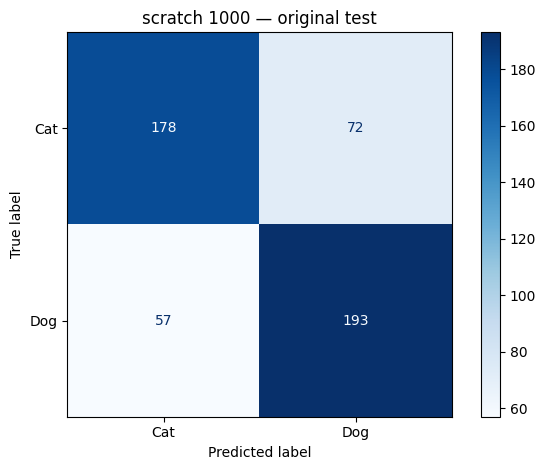

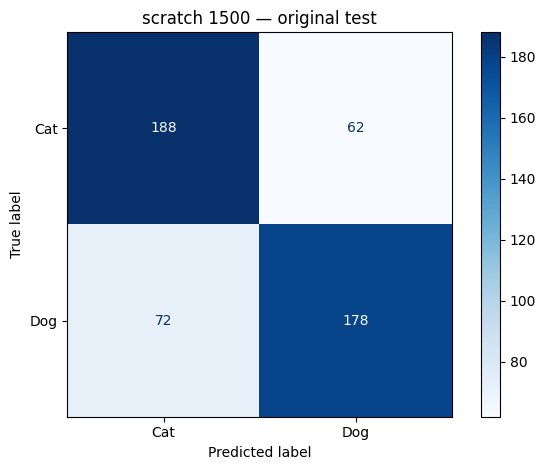

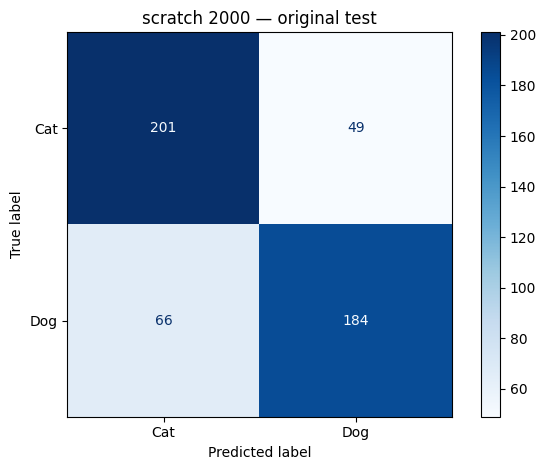

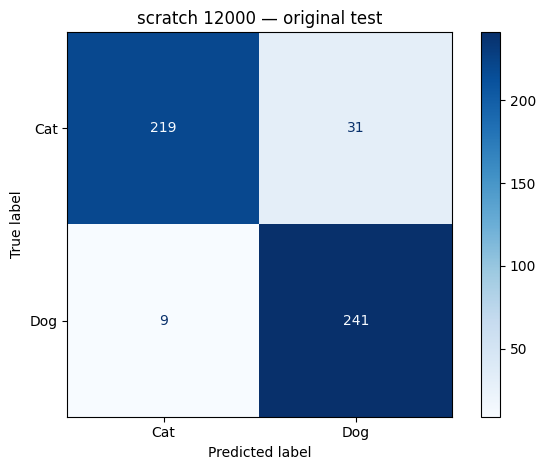

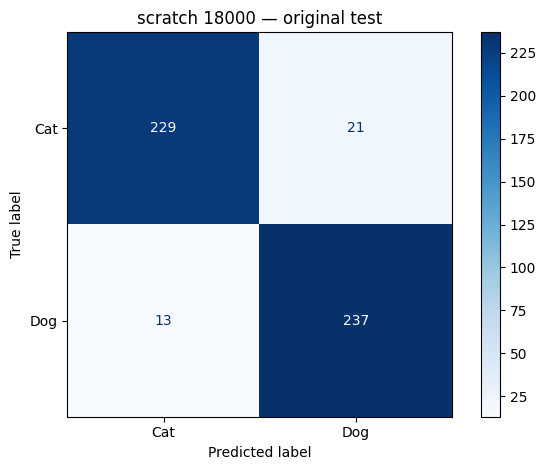

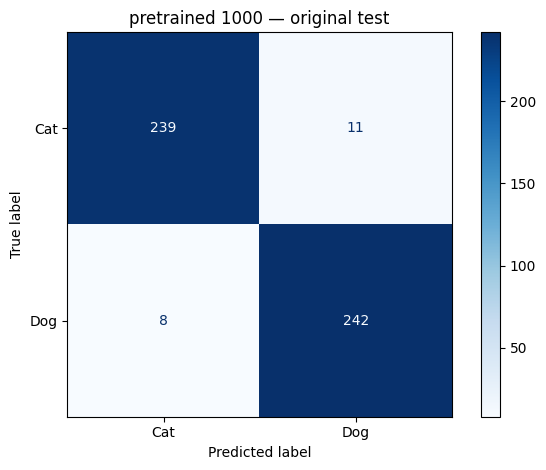

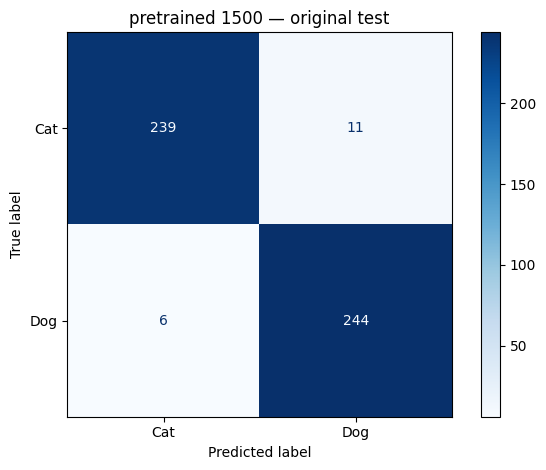

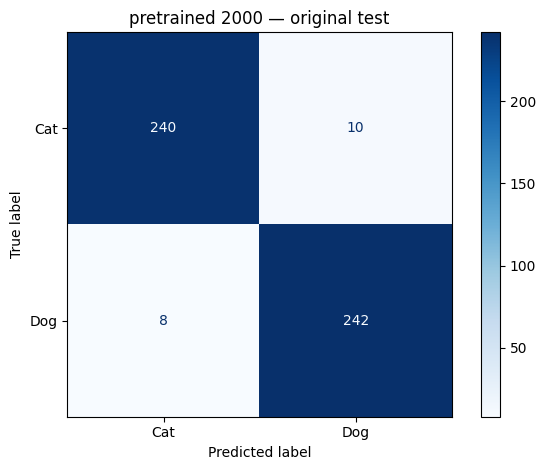

ALL EIGHT TRAINED MODELS — ORIGINAL 500-IMAGE TEST


,Model Type,Training Images,Validation Accuracy (%),Original Test Accuracy (%),Test Loss,Precision,Recall,F1 Score,Incorrect
0,Pretrained,1000,97.4,96.2,0.0857,0.9565,0.968,0.9622,19
1,Pretrained,1500,97.4,96.6,0.0787,0.9569,0.976,0.9663,17
2,Pretrained,2000,97.6,96.4,0.0699,0.9603,0.968,0.9641,18
3,Scratch,1000,76.8,74.2,0.5727,0.7283,0.772,0.7495,129
4,Scratch,1500,77.0,73.2,0.5690,0.7417,0.712,0.7265,134
5,Scratch,2000,79.2,77.0,0.4865,0.7897,0.736,0.7619,115
6,Scratch,12000,89.4,92.0,0.1990,0.8860,0.964,0.9234,40
7,Scratch,18000,92.2,93.2,0.1726,0.9186,0.948,0.9331,34


In [10]:
def evaluate_saved_model(model_path, frame, tag, folder, save_confusion=True):
    folder=Path(folder)
    folder.mkdir(parents=True,exist_ok=True)
    result_path=folder/f'{tag}_metrics.csv'
    model_path=Path(model_path)
    assert model_path.exists(),model_path
    sha=checkpoint_sha256(model_path)
    split_sha=fingerprint_names(frame)
    if result_path.exists():
        old=pd.read_csv(result_path).iloc[0]
        if old.get('model_sha256') != sha or old.get('evaluation_split_sha256') != split_sha:
            raise RuntimeError(f'Stale evaluation result: {result_path}. Archive it before any new evaluation.')
        print('VERIFIED cached evaluation:',tag)
        return old.to_dict()

    tf.keras.backend.clear_session()
    model=tf.keras.models.load_model(str(model_path))
    ds=make_dataset(frame,training=False)
    loss,accuracy=model.evaluate(ds,verbose=0)
    prob=model.predict(ds,verbose=0).reshape(-1)
    pred=(prob>=0.5).astype(int)
    true=frame['label'].map(LABELS).to_numpy(dtype=int)
    assert len(pred)==len(true)
    assert abs(float(accuracy)-float(accuracy_score(true,pred)))<0.001
    result={'model':tag,'images':len(frame),'accuracy':float(accuracy),
            'loss':float(loss),'precision':float(precision_score(true,pred,zero_division=0)),
            'recall':float(recall_score(true,pred,zero_division=0)),
            'f1':float(f1_score(true,pred,zero_division=0)),
            'incorrect':int(np.sum(true!=pred)),
            'model_sha256':sha,'evaluation_split_sha256':split_sha}
    pd.DataFrame([result]).to_csv(result_path,index=False)
    pd.DataFrame({'filename':frame['filename'].to_numpy(),
                  'actual':true,'predicted':pred,'dog_probability':prob,
                  'is_wrong':pred!=true}).to_csv(folder/f'{tag}_predictions.csv',index=False)
    if save_confusion:
        cm=confusion_matrix(true,pred,labels=[0,1])
        disp=ConfusionMatrixDisplay(cm,display_labels=['Cat','Dog'])
        disp.plot(cmap='Blues',values_format='d')
        plt.title(tag.replace('_',' ')+' — original test' if len(frame)==500 else tag.replace('_',' ')+' — holdout')
        plt.tight_layout()
        plt.savefig(folder/f'{tag}_confusion.png',dpi=180,bbox_inches='tight')
        plt.show()
    del model
    gc.collect()
    return result

all8_specs=[('Scratch',1000,CORE_FOLDERS[('Scratch',1000)]),
            ('Scratch',1500,CORE_FOLDERS[('Scratch',1500)]),
            ('Scratch',2000,CORE_FOLDERS[('Scratch',2000)]),
            ('Scratch',12000,EXT/'cnn_12000'),('Scratch',18000,EXT/'cnn_18000'),
            ('Pretrained',1000,CORE_FOLDERS[('Pretrained',1000)]),
            ('Pretrained',1500,CORE_FOLDERS[('Pretrained',1500)]),
            ('Pretrained',2000,CORE_FOLDERS[('Pretrained',2000)])]

eight_rows=[]
for kind,n,folder in all8_specs:
    model_path=folder/'best_model.keras'
    summary=pd.read_csv(folder/'results_summary.csv').iloc[0]
    expected=float(summary['original_val_accuracy'] if n>=12000 else summary['best_val_accuracy'])
    # Lightweight validation re-check with selected weights, before reusing any saved test results.
    check_model=tf.keras.models.load_model(str(model_path))
    _,observed=check_model.evaluate(make_dataset(val_frame),verbose=0)
    assert abs(expected-observed)<0.002, f'Validation checkpoint mismatch: {folder}'
    del check_model
    gc.collect()
    tag=f'{kind.lower()}_{n}'
    r=evaluate_saved_model(model_path,test_frame,tag,FINAL,save_confusion=True)
    eight_rows.append({
        'Model Type':kind,'Training Images':n,
        'Validation Accuracy (%)':round(observed*100,2),
        'Original Test Accuracy (%)':round(float(r['accuracy'])*100,2),
        'Test Loss':round(float(r['loss']),4),
        'Precision':round(float(r['precision']),4),
        'Recall':round(float(r['recall']),4),
        'F1 Score':round(float(r['f1']),4),
        'Incorrect':int(r['incorrect']),
        'model_sha256':r['model_sha256']})
all8_results=pd.DataFrame(eight_rows).sort_values(['Model Type','Training Images']).reset_index(drop=True)
all8_results.to_csv(FINAL/'all_eight_test_results.csv',index=False)
all8_results.query('`Training Images` <= 2000').to_csv(
    FINAL/'all_six_core_test_results.csv',index=False)
print('ALL EIGHT TRAINED MODELS — ORIGINAL 500-IMAGE TEST')
display(all8_results.drop(columns=['model_sha256']))

## 8. Supplementary generalization — independent 2,000-image model holdout

Evaluate the **four prespecified** models (scratch 2K, 12K, 18K; pretrained 2K) on a different 2,000-image cohort (**holdout 1**). The two holdouts in this project should never be merged or described as the same dataset. Reusing these images in an error-analysis gallery is descriptive, not a new independent test.

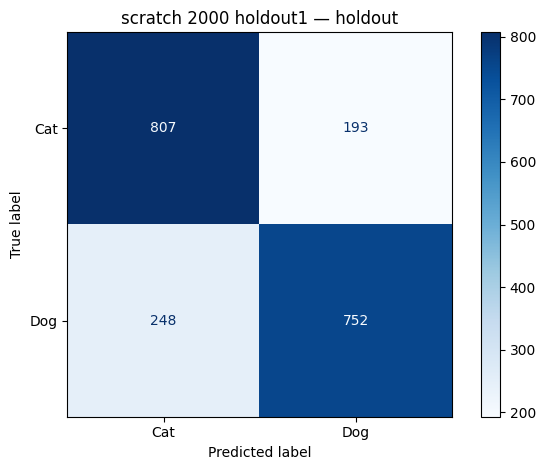

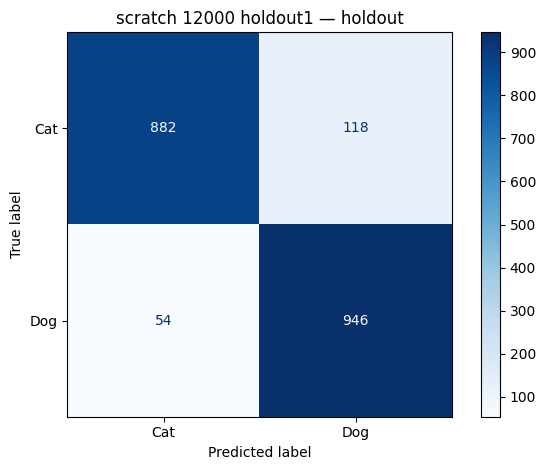

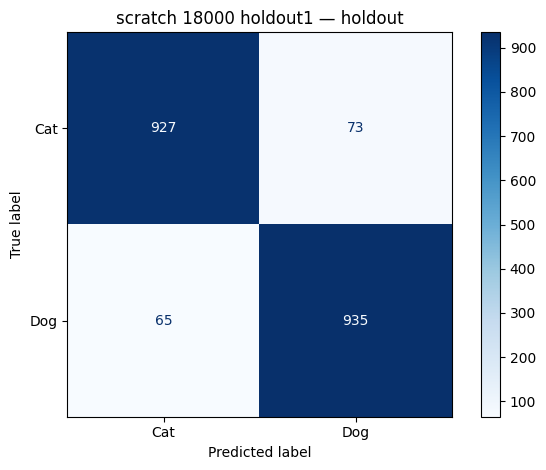

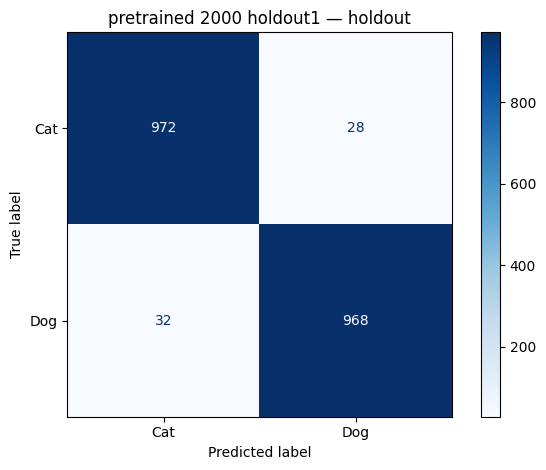

SUPPLEMENTARY MODEL HOLDOUT 1 (2,000 IMAGES)


,Model Type,Training Images,Holdout 1 Accuracy (%),Holdout 1 Loss,Holdout 1 F1,Incorrect
0,Scratch,2000,77.95,0.4630,0.7733,441
1,Scratch,12000,91.40,0.2297,0.9167,172
2,Scratch,18000,93.10,0.1806,0.9313,138
3,Pretrained,2000,97.00,0.0788,0.9699,60


In [11]:
model_holdout_specs=[('Scratch',2000,CORE_FOLDERS[('Scratch',2000)]),
                     ('Scratch',12000,EXT/'cnn_12000'),
                     ('Scratch',18000,EXT/'cnn_18000'),
                     ('Pretrained',2000,CORE_FOLDERS[('Pretrained',2000)])]
holdout_root=ROOT/'additional_holdout_evaluation'
holdout_rows=[]
for kind,n,folder in model_holdout_specs:
    tag=f'{kind.lower()}_{n}_holdout1'
    r=evaluate_saved_model(folder/'best_model.keras',holdout1,tag,holdout_root,save_confusion=True)
    holdout_rows.append({'Model Type':kind,'Training Images':n,
                         'Holdout 1 Accuracy (%)':round(float(r['accuracy'])*100,2),
                         'Holdout 1 Loss':round(float(r['loss']),4),
                         'Holdout 1 F1':round(float(r['f1']),4),
                         'Incorrect':int(r['incorrect'])})
holdout_results=pd.DataFrame(holdout_rows)
holdout_results.to_csv(holdout_root/'additional_holdout_results_clean.csv',index=False)
print('SUPPLEMENTARY MODEL HOLDOUT 1 (2,000 IMAGES)')
display(holdout_results)

## 9. Supplementary study — dropout 0.0, 0.25 and 0.50

Hold architecture, training data, augmentation, learning rate and all **25 epochs** constant. Three independently initialized scratch CNNs (2,000 training images, seed=42) vary **only the dropout rate**, using original validation loss to select each best checkpoint. All three configurations were prescribed before viewing the separate **dropout-specific holdout 2**; subsequent testing is descriptive and will **not** change the original selected settings.

In [12]:
DROP_ROOT=ROOT/'dropout_experiments'
DROP_ROOT.mkdir(parents=True,exist_ok=True)

def run_dropout_study(rate,seed,folder):
    folder=Path(folder)
    folder.mkdir(parents=True,exist_ok=True)
    best=folder/'best_model.keras'
    hist=folder/'training_history.csv'
    results_path=folder/'result.csv'  # original result, if present
    standardized_path=folder/'result_standardized.csv'  # new output; never overwrite original
    # The historical project uses 'result.csv' for repeated seeds and a global
    # 'dropout_comparison.csv' for the first three runs. Both formats are supported.
    if best.exists() or hist.exists():
        if not (best.exists() and hist.exists()):
            raise RuntimeError(f'Incomplete old dropout run in {folder}; do not overwrite.')
        h=pd.read_csv(hist)
        assert len(h)==EPOCHS
        best_epoch=int(h['val_loss'].idxmin())+1
        model=tf.keras.models.load_model(str(best))
        val_loss,val_acc=model.evaluate(make_dataset(val_frame),verbose=0)
        _,train_acc=model.evaluate(make_dataset(q3),verbose=0)
        if results_path.exists():
            old=pd.read_csv(results_path).iloc[0]
            # 'result.csv' from the three-seed study uses human-readable percentages.
            if 'Validation Accuracy (%)' in old.index:
                assert abs(float(old['Validation Accuracy (%)'])-val_acc*100)<0.2
        print(f'REUSED dropout={rate} seed={seed}; validation={val_acc*100:.2f}%')
    else:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)
        ds=make_dataset(q3,training=True,seed=seed)
        model=build_scratch(dropout=rate)
        checkpoint=tf.keras.callbacks.ModelCheckpoint(
            str(best),monitor='val_loss',save_best_only=True,mode='min',verbose=0)
        fitted=model.fit(ds,validation_data=make_dataset(val_frame),
                         epochs=EPOCHS,callbacks=[checkpoint],verbose=0)
        h=pd.DataFrame(fitted.history)
        h.to_csv(hist,index=False)
        best_epoch=int(h['val_loss'].idxmin())+1
        del model
        model=tf.keras.models.load_model(str(best))
        val_loss,val_acc=model.evaluate(make_dataset(val_frame),verbose=0)
        _,train_acc=model.evaluate(make_dataset(q3),verbose=0)
        print(f'TRAINED dropout={rate} seed={seed}; validation={val_acc*100:.2f}%')
    result={'Dropout Rate':rate,'Seed':seed,'Best Epoch':best_epoch,
            'Training Accuracy (%)':round(train_acc*100,4),
            'Validation Accuracy (%)':round(val_acc*100,4),
            'Validation Loss':round(float(val_loss),6),
            'Accuracy Gap (points)':round((train_acc-val_acc)*100,4),
            'model_sha256':checkpoint_sha256(best)}
    if results_path.exists():
        # Overwrite only the standardized result CSV, never the model/history.
        old=pd.read_csv(results_path).iloc[0]
        if 'Seed' in old.index:
            assert int(old['Seed'])==seed
    pd.DataFrame([result]).to_csv(standardized_path,index=False)
    del model
    gc.collect()
    return result

dropout_rows=[]
for rate in (0.0,0.25,0.5):
    folder=DROP_ROOT/f"dropout_{str(rate).replace('.','p')}"
    dropout_rows.append(run_dropout_study(rate,42,folder))
dropout_results=pd.DataFrame(dropout_rows)
dropout_results.to_csv(DROP_ROOT/'dropout_comparison_standardized.csv',index=False)
display(dropout_results.drop(columns=['model_sha256']))

TRAINED dropout=0.0 seed=42; validation=79.60%
TRAINED dropout=0.25 seed=42; validation=79.80%
TRAINED dropout=0.5 seed=42; validation=80.20%


,Dropout Rate,Seed,Best Epoch,Training Accuracy (%),Validation Accuracy (%),Validation Loss,Accuracy Gap (points)
0,0.00,42,24,88.95,79.6,0.427593,9.35
1,0.25,42,25,87.00,79.8,0.430374,7.20
2,0.50,42,25,86.75,80.2,0.418397,6.55


### 9.1 Additional **dropout-specific** holdout (2,000 images)

This is **holdout 2**, not the image set used to compare the four main CNN models. It was reserved independently and its results should not be used to choose a dropout rate after observing them.

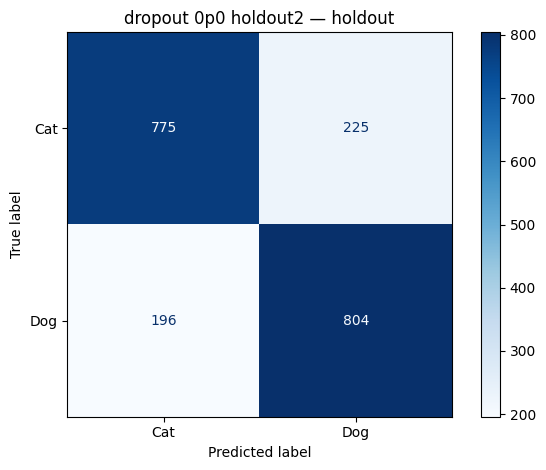

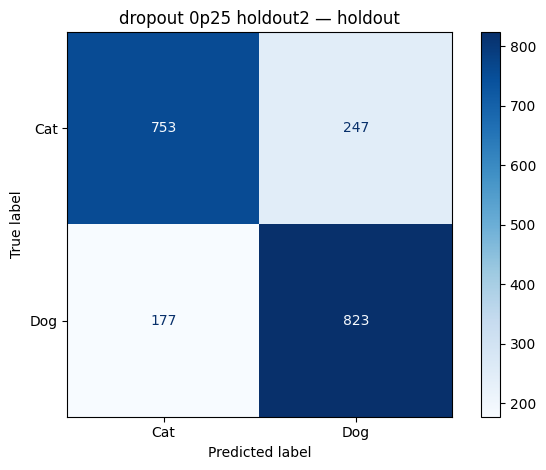

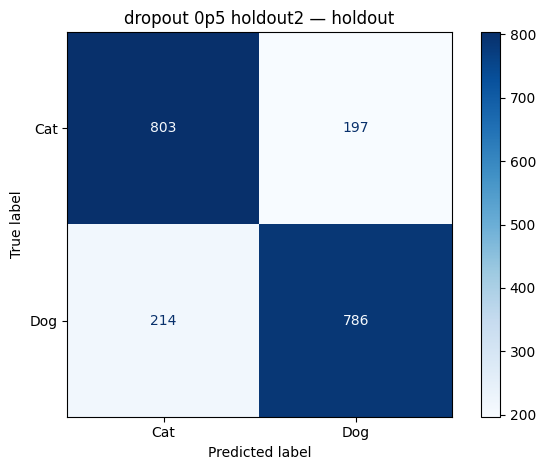

,Dropout Rate,Test Images,Holdout 2 Accuracy (%),Holdout 2 Loss,Precision,Recall,F1 Score,Incorrect
0,0.00,2000,78.95,0.4638,0.7813,0.804,0.7925,421
1,0.25,2000,78.80,0.4667,0.7692,0.823,0.7952,424
2,0.50,2000,79.45,0.4571,0.7996,0.786,0.7927,411


In [13]:
dropout_holdout_rows=[]
for rate in (0.0,0.25,0.5):
    model=DROP_ROOT/f"dropout_{str(rate).replace('.','p')}"/'best_model.keras'
    tag='dropout_'+str(rate).replace('.','p')+'_holdout2'
    r=evaluate_saved_model(model,holdout2,tag,DROP_ROOT/'new_holdout_results',save_confusion=True)
    dropout_holdout_rows.append({'Dropout Rate':rate,'Test Images':len(holdout2),
                                 'Holdout 2 Accuracy (%)':round(float(r['accuracy'])*100,2),
                                 'Holdout 2 Loss':round(float(r['loss']),4),
                                 'Precision':round(float(r['precision']),4),
                                 'Recall':round(float(r['recall']),4),
                                 'F1 Score':round(float(r['f1']),4),
                                 'Incorrect':int(r['incorrect'])})
dropout_holdout_results=pd.DataFrame(dropout_holdout_rows)
dropout_holdout_results.to_csv(DROP_ROOT/'unused_holdout_results_standardized.csv',index=False)
display(dropout_holdout_results)

## 10. Supplementary study — nine random-seed repeats

Repeat each dropout configuration across three **predetermined** random seeds `17, 42, 123`, retaining the exact 2,000-image training set and original 500-image validation set. Summarize mean, sample standard deviation (`ddof=1`) and mean generalization gap. Three seeds give a preliminary stability check, not a significance test.

In [14]:
SEEDS=(17,42,123)
RATES=(0.0,0.25,0.5)
seed_root=ROOT/'dropout_seed_study'
seed_root.mkdir(parents=True,exist_ok=True)
seed_rows=[]
for rate in RATES:
    for seed in SEEDS:
        folder=seed_root/f'dropout_{rate}_seed_{seed}'
        r=run_dropout_study(rate,seed,folder)
        seed_rows.append({'Dropout':rate,'Seed':seed,'Best Epoch':r['Best Epoch'],
                          'Training Accuracy (%)':r['Training Accuracy (%)'],
                          'Validation Accuracy (%)':r['Validation Accuracy (%)'],
                          'Validation Loss':r['Validation Loss'],
                          'Accuracy Gap':r['Accuracy Gap (points)']})
seed_results=pd.DataFrame(seed_rows)
seed_summary=seed_results.groupby('Dropout').agg(
    Mean_Accuracy=('Validation Accuracy (%)','mean'),
    Std_Accuracy=('Validation Accuracy (%)','std'),
    Mean_Loss=('Validation Loss','mean'),
    Std_Loss=('Validation Loss','std'),
    Mean_Gap=('Accuracy Gap','mean')).reset_index()
seed_results.to_csv(seed_root/'all_seed_results.csv',index=False)
seed_summary.to_csv(seed_root/'seed_stability_summary.csv',index=False)
print('ALL NINE PREDETERMINED REPEATS')
display(seed_results.round(3))
print('MEAN AND SAMPLE STANDARD DEVIATION')
display(seed_summary.round(4))

TRAINED dropout=0.0 seed=17; validation=78.60%
TRAINED dropout=0.0 seed=42; validation=79.60%
TRAINED dropout=0.0 seed=123; validation=80.00%
TRAINED dropout=0.25 seed=17; validation=79.60%
TRAINED dropout=0.25 seed=42; validation=78.80%
TRAINED dropout=0.25 seed=123; validation=79.60%
TRAINED dropout=0.5 seed=17; validation=79.00%
TRAINED dropout=0.5 seed=42; validation=80.60%
TRAINED dropout=0.5 seed=123; validation=79.40%
ALL NINE PREDETERMINED REPEATS


,Dropout,Seed,Best Epoch,Training Accuracy (%),Validation Accuracy (%),Validation Loss,Accuracy Gap
0,0.00,17,25,88.80,78.6,0.445,10.20
1,0.00,42,25,88.60,79.6,0.421,9.00
2,0.00,123,25,90.05,80.0,0.425,10.05
3,0.25,17,25,88.05,79.6,0.430,8.45
4,0.25,42,24,87.35,78.8,0.436,8.55
5,0.25,123,24,88.15,79.6,0.431,8.55
6,0.50,17,25,87.15,79.0,0.421,8.15
7,0.50,42,25,86.90,80.6,0.432,6.30
8,0.50,123,25,86.85,79.4,0.438,7.45


MEAN AND SAMPLE STANDARD DEVIATION


,Dropout,Mean_Accuracy,Std_Accuracy,Mean_Loss,Std_Loss,Mean_Gap
0,0.00,79.4000,0.7211,0.4301,0.0127,9.7500
1,0.25,79.3333,0.4619,0.4324,0.0035,8.5167
2,0.50,79.6667,0.8327,0.4303,0.0085,7.3000


## 11. Error analysis, false-confidence cases, and dataset quality

Use the same **holdout 1** (2,000 images) for all four models. Save the prediction probability, confidence in the chosen class, a wrong/right flag, and counts of shared mistakes. Do not assume a high-confidence incorrect *dataset-label match* implies that the visual model decision is incorrect: inspect source images manually. **Do not silently relabel benchmark images or adjust the main test results.**

In [15]:
error_models={
    'scratch_2k':CORE_FOLDERS[('Scratch',2000)]/'best_model.keras',
    'scratch_12k':EXT/'cnn_12000'/'best_model.keras',
    'scratch_18k':EXT/'cnn_18000'/'best_model.keras',
    'pretrained_2k':CORE_FOLDERS[('Pretrained',2000)]/'best_model.keras'
}
error_root=ROOT/'misclassification_study'
error_root.mkdir(parents=True,exist_ok=True)
analysis=holdout1.reset_index(drop=True).copy()
truth=analysis['label'].map(LABELS).to_numpy(dtype=int)
model_error_summary=[]
for name,path in error_models.items():
    tag='pretrained_2000_holdout1' if name=='pretrained_2k' else (
        'scratch_'+name.split('_')[1].replace('k','000')+'_holdout1')
    pred_path=ROOT/'additional_holdout_evaluation'/f'{tag}_predictions.csv'
    # The evaluation cell above has already produced immutable, checksum-keyed predictions.
    assert pred_path.exists(), pred_path
    pred_df=pd.read_csv(pred_path)
    assert pred_df['filename'].tolist()==analysis['filename'].tolist(), 'Holdout prediction order mismatch'
    probability=pred_df['dog_probability'].to_numpy(dtype=float)
    predicted=(probability>=0.5).astype(int)
    wrong=predicted!=truth
    confidence=np.where(predicted==1,probability,1-probability)
    analysis[f'prediction_{name}']=predicted
    analysis[f'probability_{name}']=probability
    analysis[f'confidence_{name}']=confidence
    analysis[f'wrong_{name}']=wrong
    model_error_summary.append({'Model':name,'Correct':int((~wrong).sum()),
                                'Incorrect':int(wrong.sum()),
                                'Accuracy (%)':round((~wrong).mean()*100,2)})
error_summary=pd.DataFrame(model_error_summary)
analysis.to_csv(error_root/'all_predictions.csv',index=False)
error_summary.to_csv(error_root/'error_summary.csv',index=False)
display(error_summary)

both_wrong=analysis[analysis['wrong_scratch_18k'] & analysis['wrong_pretrained_2k']].copy()
pretrained_correct=analysis[analysis['wrong_scratch_18k'] & ~analysis['wrong_pretrained_2k']].copy()
scratch_correct=analysis[~analysis['wrong_scratch_18k'] & analysis['wrong_pretrained_2k']].copy()
all_four_wrong=analysis[analysis[[f'wrong_{n}' for n in error_models]].all(axis=1)].copy()
for name,frame in [
    ('both_wrong',both_wrong),('pretrained_fixes',pretrained_correct),
    ('scratch_fixes',scratch_correct),('all_four_wrong',all_four_wrong)]:
    frame.to_csv(error_root/f'{name}.csv',index=False)
print('Both scratch 18K and pretrained wrong:',len(both_wrong))
print('Scratch 18K wrong, pretrained correct:',len(pretrained_correct))
print('Pretrained wrong, scratch 18K correct:',len(scratch_correct))
print('All four wrong:',len(all_four_wrong))
assert len(both_wrong)+len(pretrained_correct)==int(error_summary.query("Model=='scratch_18k'")['Incorrect'].iloc[0])
assert len(both_wrong)+len(scratch_correct)==int(error_summary.query("Model=='pretrained_2k'")['Incorrect'].iloc[0])

,Model,Correct,Incorrect,Accuracy (%)
0,scratch_2k,1559,441,77.95
1,scratch_12k,1828,172,91.40
2,scratch_18k,1862,138,93.10
3,pretrained_2k,1940,60,97.00


Both scratch 18K and pretrained wrong: 23
Scratch 18K wrong, pretrained correct: 115
Pretrained wrong, scratch 18K correct: 37
All four wrong: 14


### 11.1 Error galleries (all scratch models and pretrained)

The following plots show **recorded model predictions**, not automatically corrected labels. A picture with no cat or dog (e.g. a commercial logo) is an *out-of-scope example* that a binary classifier must nevertheless place in one of its two categories. The same image can recur across *overlapping error categories* without appearing in multiple data splits.

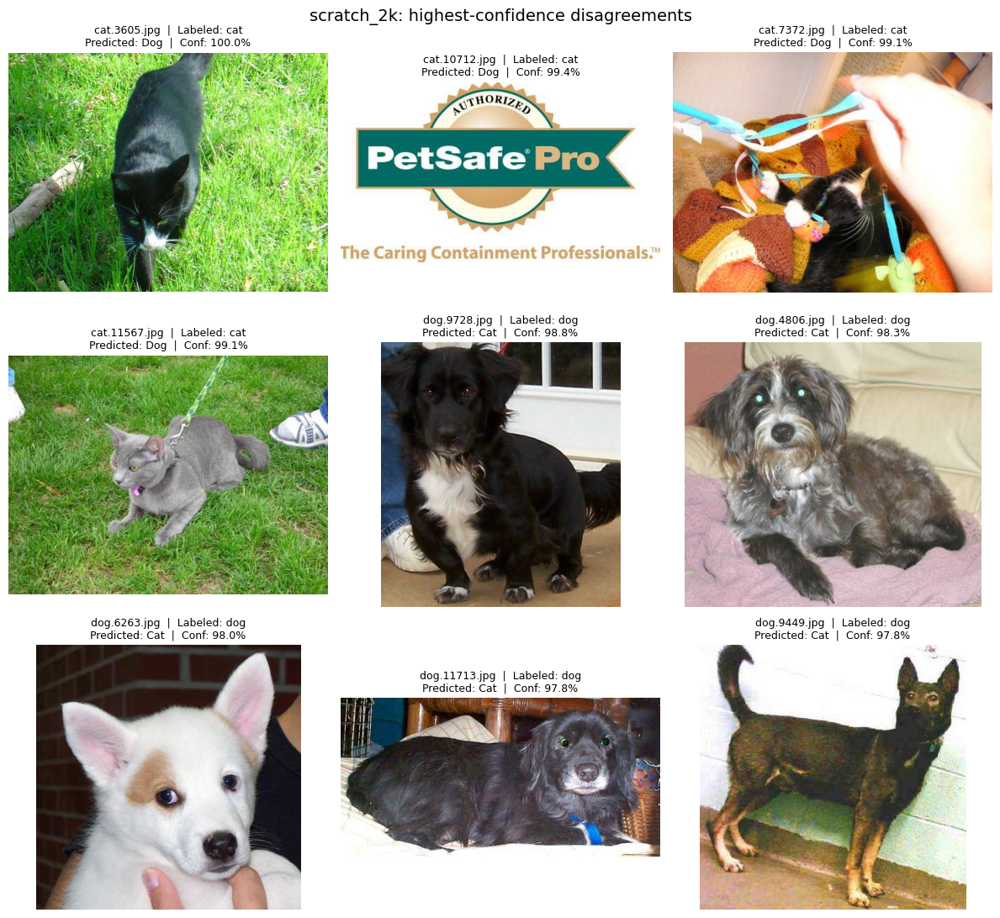

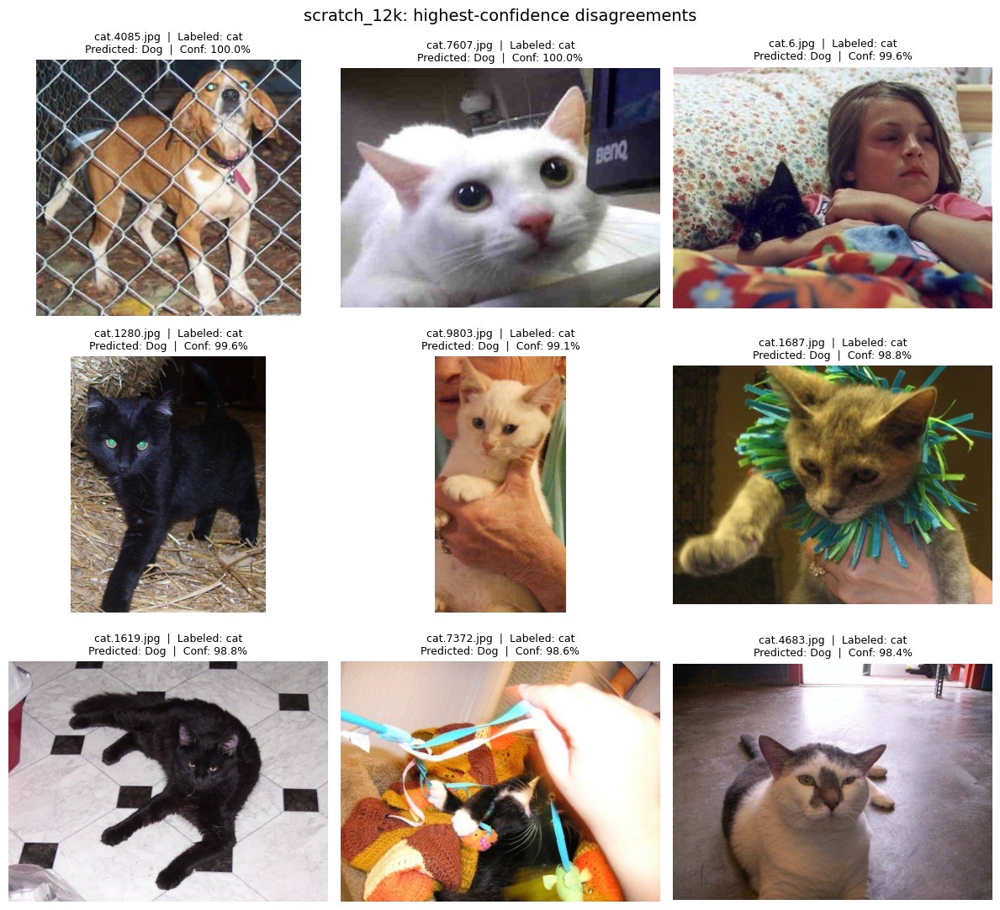

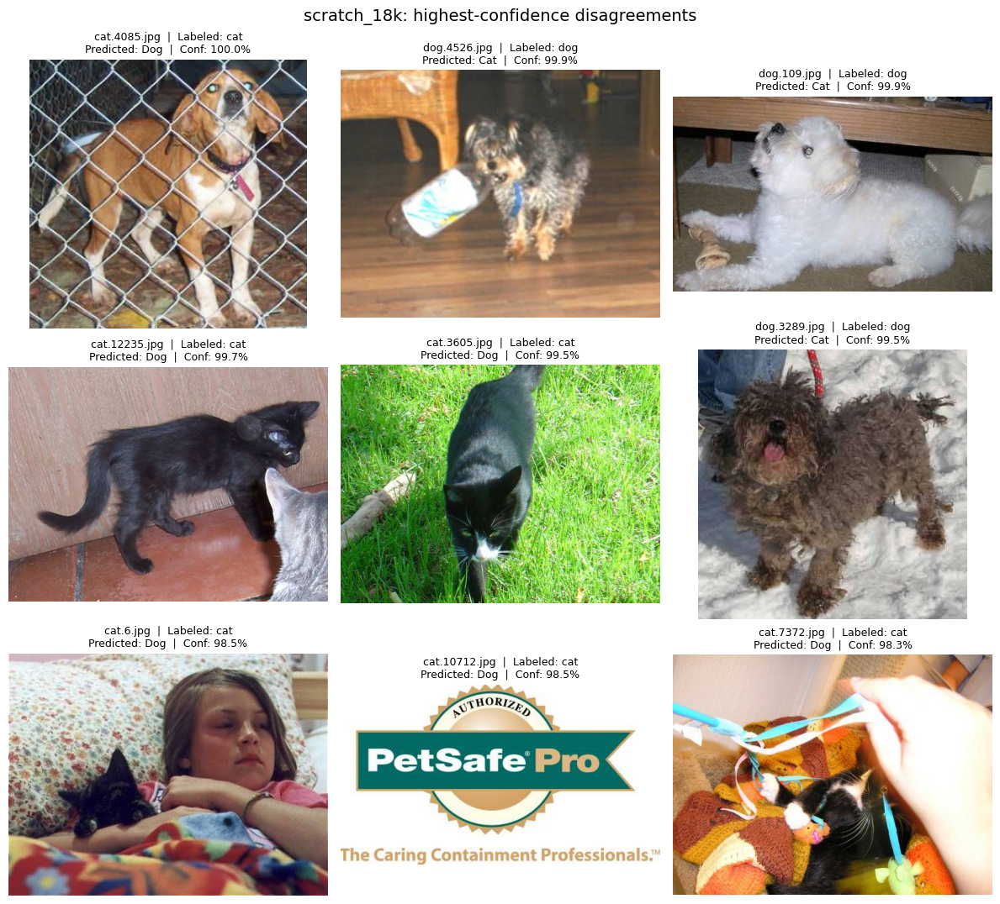

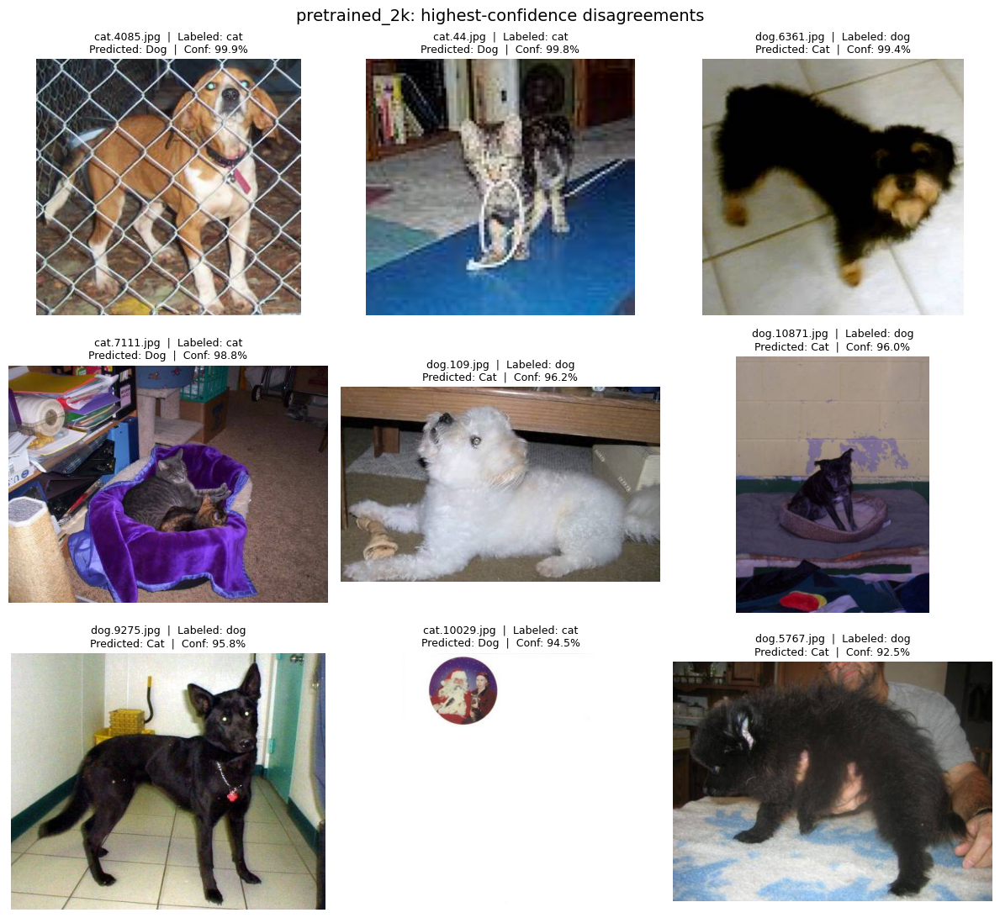

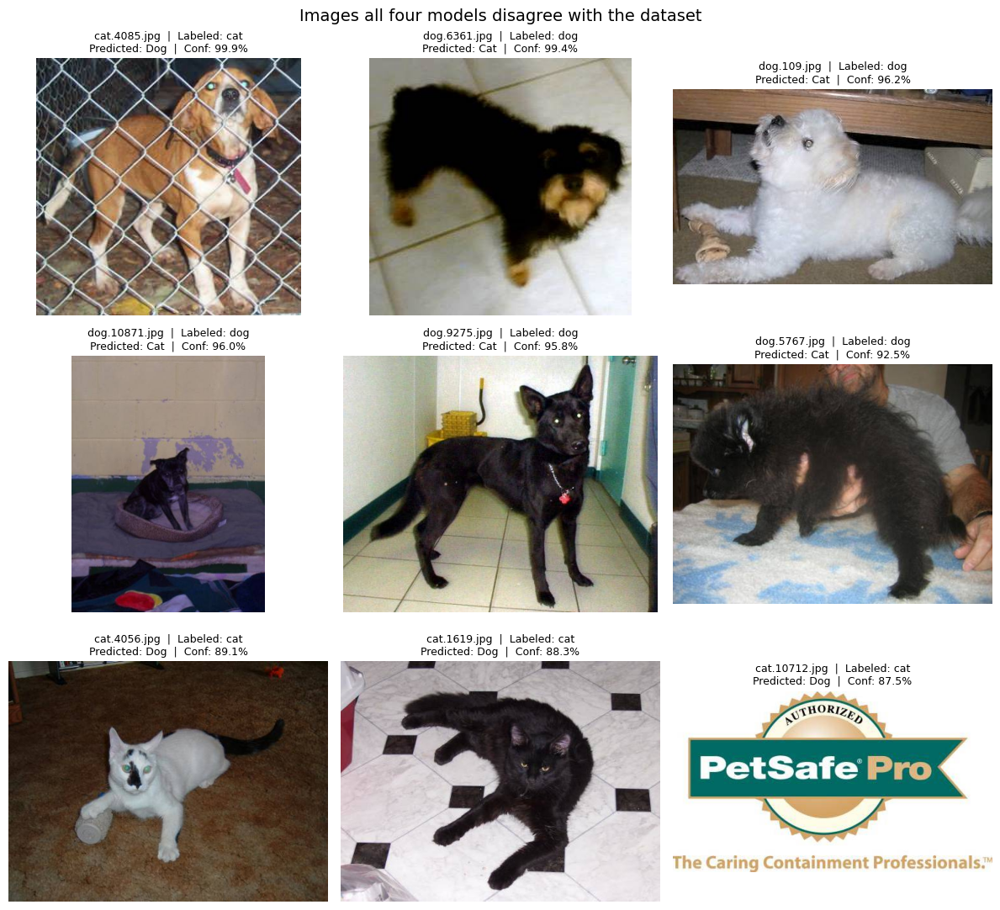

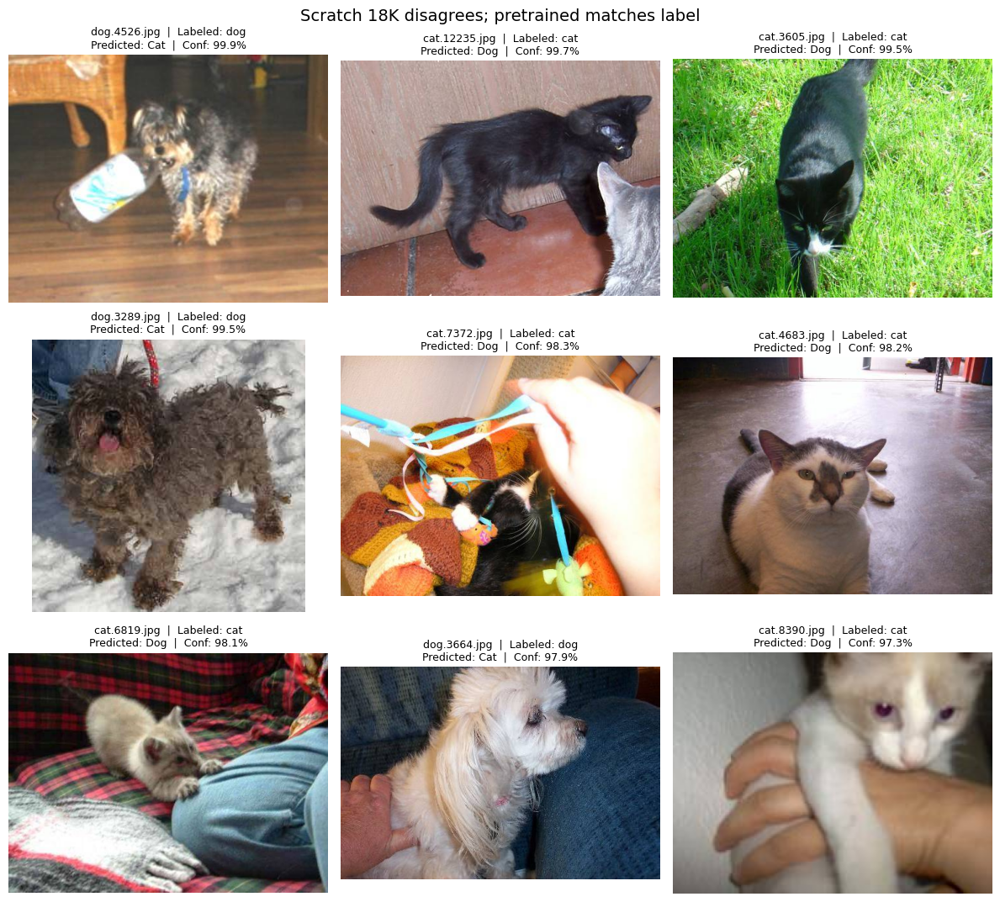

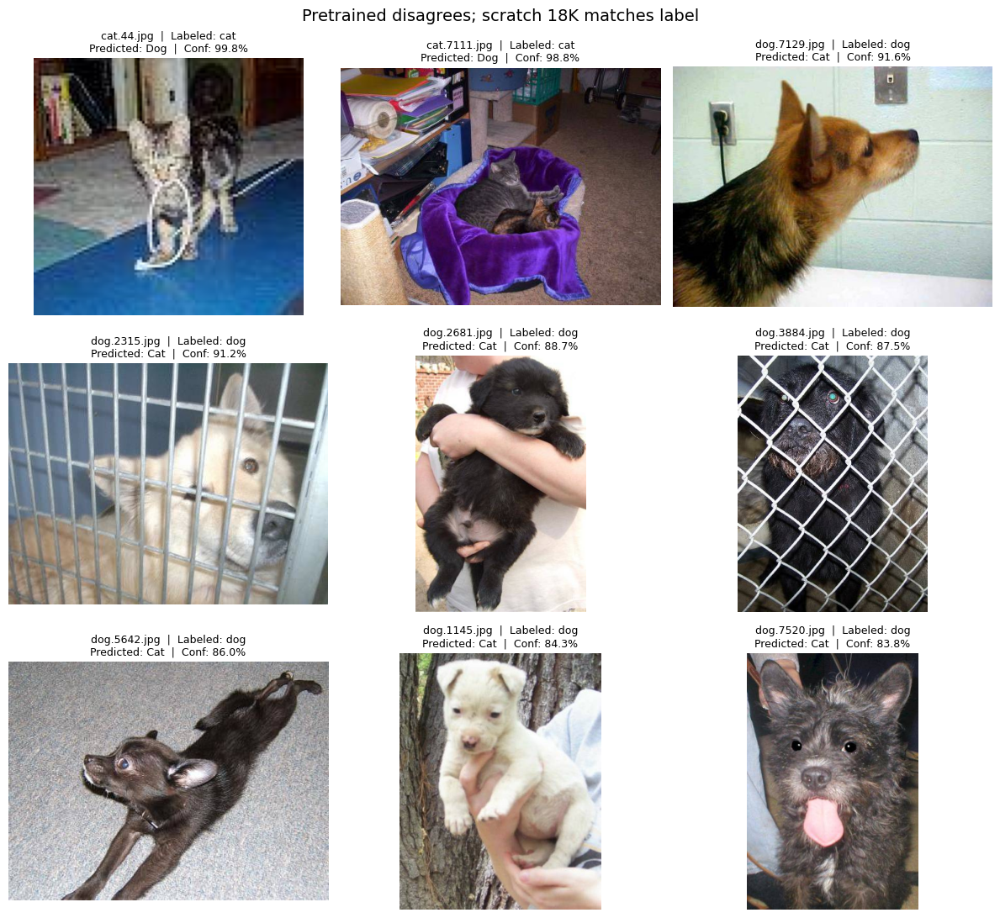

In [16]:
def show_gallery(df, model_name, title, target_filename, top_n=9):
    if len(df)==0:
        print('No examples in:',title)
        return
    sample=df.sort_values(f'confidence_{model_name}',ascending=False).head(top_n)
    rows=int(np.ceil(len(sample)/3))
    fig,axes=plt.subplots(rows,3,figsize=(12,3.7*rows))
    axes=np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis('off')
    for ax,(_,r) in zip(axes,sample.iterrows()):
        with Image.open(r.image_path) as img:
            ax.imshow(img.convert('RGB'))
        pred='Dog' if int(r[f'prediction_{model_name}'])==1 else 'Cat'
        conf=100*float(r[f'confidence_{model_name}'])
        ax.set_title(f'{normalize_name(r.filename)}  |  Labeled: {r.label}\n'
                     f'Predicted: {pred}  |  Conf: {conf:.1f}%',fontsize=9)
    fig.suptitle(title,fontsize=14)
    plt.tight_layout()
    plt.savefig(error_root/target_filename,dpi=180,bbox_inches='tight')
    plt.show()
    plt.close(fig)

for name in error_models:
    bad=analysis[analysis[f'wrong_{name}']]
    show_gallery(bad,name,f'{name}: highest-confidence disagreements',
                 f'{name}_error_gallery.png')
show_gallery(all_four_wrong,'pretrained_2k','Images all four models disagree with the dataset',
             'all_four_wrong_examples.png')
show_gallery(pretrained_correct,'scratch_18k',
             'Scratch 18K disagrees; pretrained matches label','pretrained_advantage_examples.png')
show_gallery(scratch_correct,'pretrained_2k',
             'Pretrained disagrees; scratch 18K matches label','scratch_advantage_examples.png')

### 11.2 Source-label audit (manual review required)

The historical analysis highlighted `train/cat.4085.jpg`, visually showing a dog although its source filename and assigned label say **cat**. The original bytes match the Kaggle archive, supporting a probable **source label error**. The scratch-error gallery also included a logo that appears to contain **neither** class. We preserve original scores; human review can be recorded in `manual_label_audit.csv` without altering the test cohorts.

Known suspicious filename: train/cat.4085.jpg
Provided class label: cat | original source bytes verified: True
Predictions:
  scratch_2k Dog confidence 97.31%
  scratch_12k Dog confidence 100.00%
  scratch_18k Dog confidence 100.00%
  pretrained_2k Dog confidence 99.87%


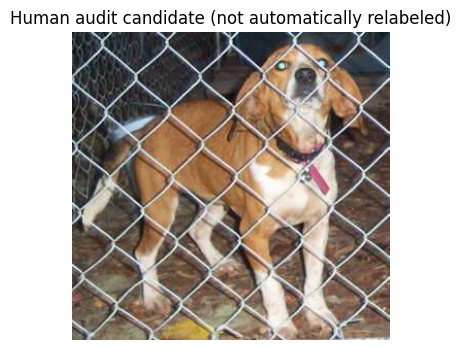

Blank human label audit created: /kaggle/working/misclassification_study/manual_label_audit.csv


In [17]:
audit_name='cat.4085.jpg'
audit_row=analysis.loc[analysis.filename.map(normalize_name).eq(audit_name)]
if len(audit_row)==1:
    row=audit_row.iloc[0]
    with zipfile.ZipFile(TRAIN_ZIP) as z:
        original=z.read(row.filename)
    local=Path(row.image_path).read_bytes()
    matches=hashlib.sha256(original).digest()==hashlib.sha256(local).digest()
    print('Known suspicious filename:',row.filename)
    print('Provided class label:',row.label,'| original source bytes verified:',matches)
    print('Predictions:')
    for name in error_models:
        pred='Dog' if int(row[f'prediction_{name}'])==1 else 'Cat'
        print(' ',name,pred, 'confidence',f'{row[f"confidence_{name}"]*100:.2f}%')
    with Image.open(row.image_path) as im:
        plt.figure(figsize=(5,4));plt.imshow(im.convert('RGB'))
        plt.title('Human audit candidate (not automatically relabeled)')
        plt.axis('off');plt.show()
else:
    print('Named audit candidate is not in the first 2,000-image holdout; no inference made.')

audit_columns=['filename','label','image_path']+[f'wrong_{n}' for n in error_models]
audit=analysis[analysis[[f'wrong_{n}' for n in error_models]].any(axis=1)][audit_columns].copy()
audit['Human Review Label']=''
audit['Issue Type']=''
audit['Reviewer Notes']=''
audit_path=error_root/'manual_label_audit.csv'
if audit_path.exists():
    print('Existing human label audit preserved:',audit_path)
else:
    audit.to_csv(audit_path,index=False)
    print('Blank human label audit created:',audit_path)

## 12. Final experiment dashboard — figures and machine-readable tables

All graphs below use **saved checkpoint-verified measurements** generated by the preceding cells. The six required models remain separate from the large-data research. The original fixed test has 500 images; holdout 1 and holdout 2 have 2,000 **different** images each. Standard-deviation error bars describe the spread over only three seeds. Figures are saved as individual PNG files alongside CSV tables.

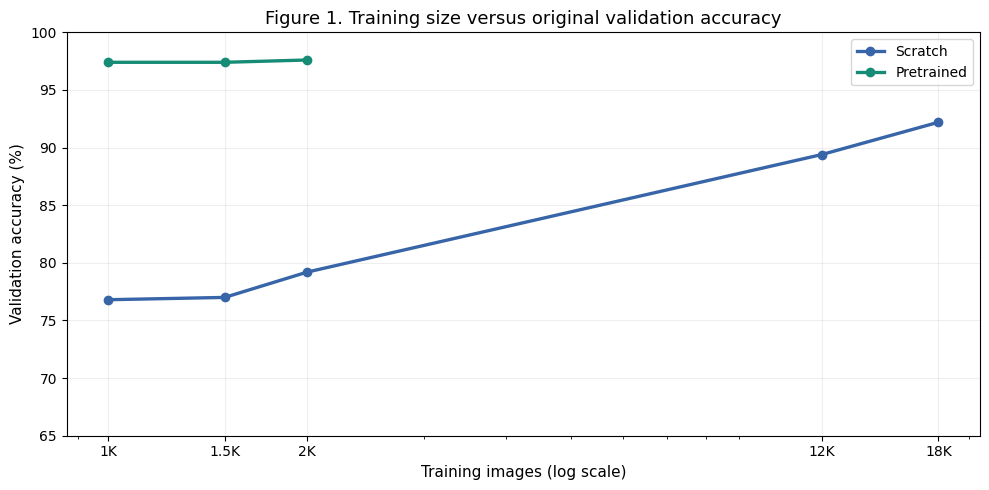

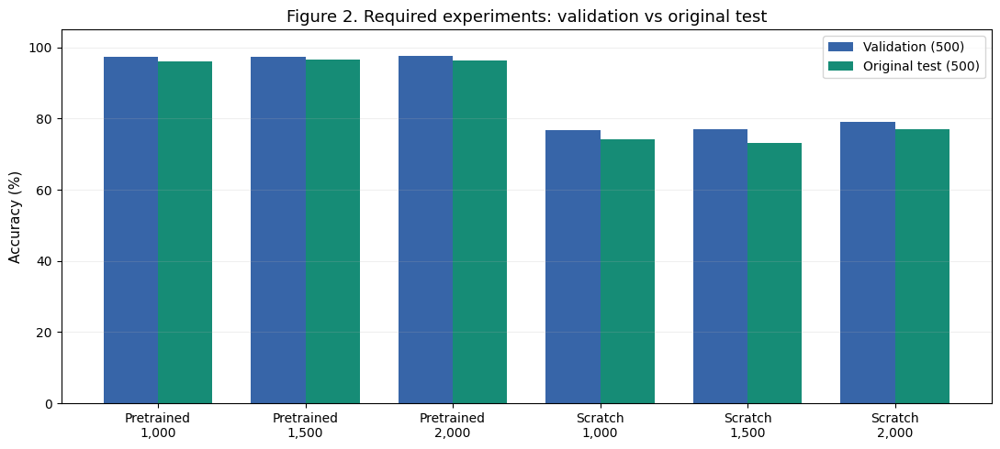

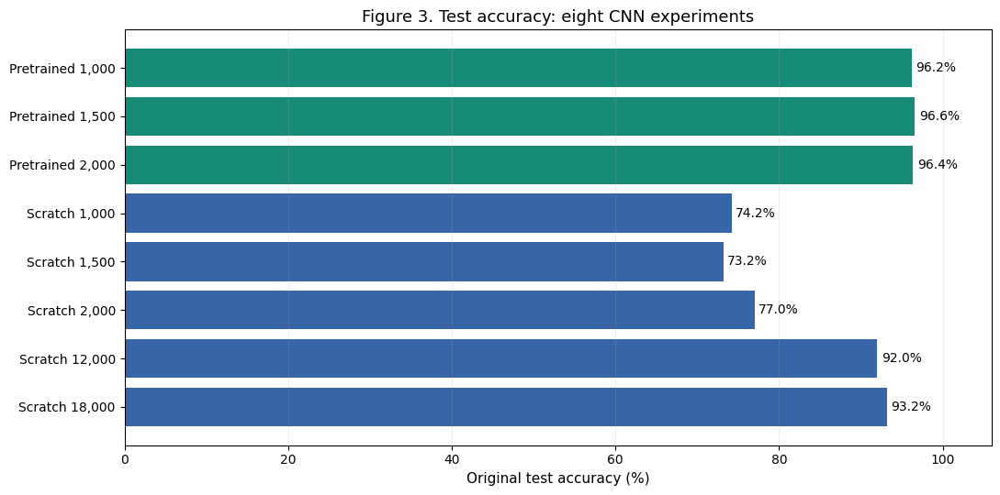

In [18]:
# Shared plot formatting and transparent figure saving.
plt.rcParams.update({'font.size':10,'axes.titlesize':13,'axes.labelsize':11})
COLORS={'Scratch':'#3765a8','Pretrained':'#168c76'}

def save_plot(name):
    plt.tight_layout()
    plt.savefig(VIS/name,dpi=200,bbox_inches='tight')
    plt.show()
    plt.close()

# Figure 1 — accuracy vs sample size (logarithmic x-scale prevents the first 3 points collapsing).
plt.figure(figsize=(10,5))
for kind in ('Scratch','Pretrained'):
    subset=all8_results[all8_results['Model Type']==kind].sort_values('Training Images')
    plt.plot(subset['Training Images'],subset['Validation Accuracy (%)'],
             marker='o',linewidth=2.4,label=kind,color=COLORS[kind])
plt.xscale('log')
plt.xticks([1000,1500,2000,12000,18000],['1K','1.5K','2K','12K','18K'])
plt.ylim(65,100);plt.grid(alpha=.2);plt.legend()
plt.xlabel('Training images (log scale)');plt.ylabel('Validation accuracy (%)')
plt.title('Figure 1. Training size versus original validation accuracy')
save_plot('01_dataset_size_vs_accuracy.png')

# Figure 2 — required six models only.
core_six=all8_results[all8_results['Training Images']<=2000].copy()
xx=np.arange(len(core_six)); width=.37
fig,ax=plt.subplots(figsize=(11,5))
ax.bar(xx-width/2,core_six['Validation Accuracy (%)'],width,label='Validation (500)',color='#3765a8')
ax.bar(xx+width/2,core_six['Original Test Accuracy (%)'],width,label='Original test (500)',color='#168c76')
ax.set_xticks(xx,[f'{k}\n{n:,}' for k,n in zip(core_six['Model Type'],core_six['Training Images'])])
ax.set_ylim(0,105);ax.set_ylabel('Accuracy (%)')
ax.set_title('Figure 2. Required experiments: validation vs original test')
ax.legend();ax.grid(axis='y',alpha=.2)
save_plot('02_six_required_validation_vs_test.png')

# Figure 3 — final original-test accuracy for all eight trained models.
rows=all8_results.sort_values(['Model Type','Training Images'])
plt.figure(figsize=(11,5.5))
labels=[f'{k} {n:,}' for k,n in zip(rows['Model Type'],rows['Training Images'])]
vals=rows['Original Test Accuracy (%)'].to_numpy()
rects=plt.barh(labels,vals,color=[COLORS[k] for k in rows['Model Type']])
plt.gca().invert_yaxis();plt.xlim(0,106)
plt.xlabel('Original test accuracy (%)');plt.title('Figure 3. Test accuracy: eight CNN experiments')
for rect,v in zip(rects,vals):
    plt.text(float(v)+.5,rect.get_y()+rect.get_height()/2,f'{v:.1f}%',va='center')
plt.grid(axis='x',alpha=.2)
save_plot('03_all_eight_test_accuracy.png')

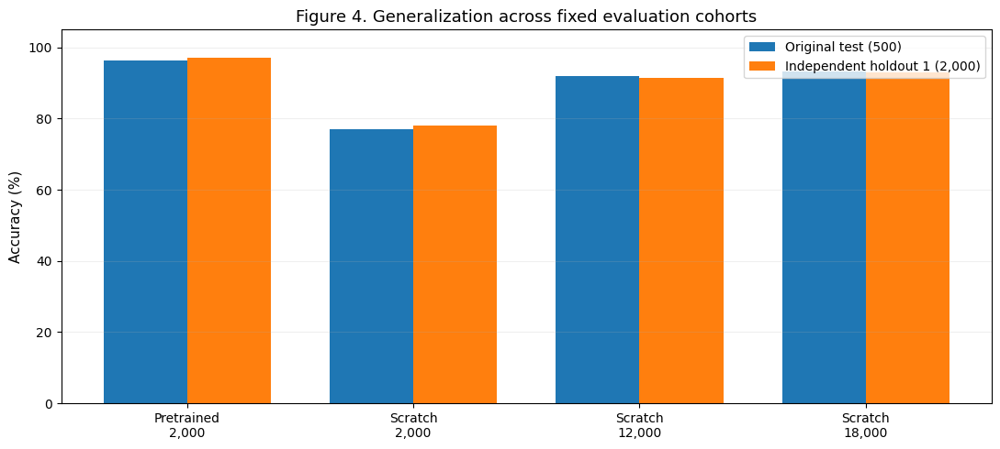

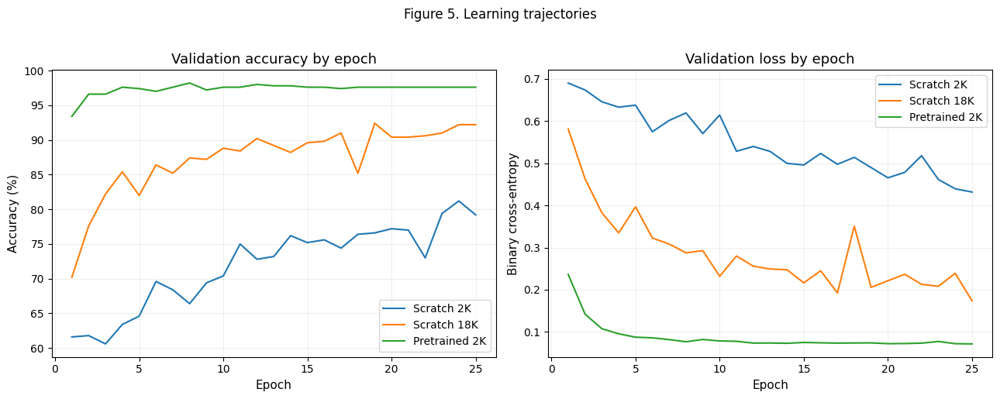

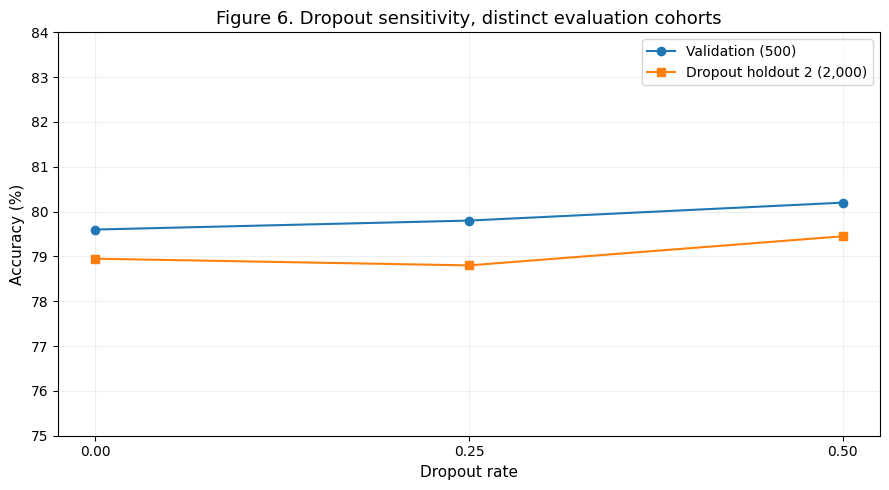

In [19]:
# Figure 4 — compare only models tested on BOTH evaluation cohorts.
joined=all8_results.merge(holdout_results,on=['Model Type','Training Images'],validate='one_to_one')
x=np.arange(len(joined)); width=.37
plt.figure(figsize=(11,5))
plt.bar(x-width/2,joined['Original Test Accuracy (%)'],width,label='Original test (500)')
plt.bar(x+width/2,joined['Holdout 1 Accuracy (%)'],width,label='Independent holdout 1 (2,000)')
plt.xticks(x,[f'{k}\n{n:,}' for k,n in zip(joined['Model Type'],joined['Training Images'])])
plt.ylim(0,105);plt.ylabel('Accuracy (%)');plt.title('Figure 4. Generalization across fixed evaluation cohorts')
plt.legend();plt.grid(axis='y',alpha=.2)
save_plot('04_test_vs_holdout1.png')

# Figure 5 — learning trajectories from checkpoint-matched histories.
selected_histories={
    'Scratch 2K':CORE_FOLDERS[('Scratch',2000)]/'training_history.csv',
    'Scratch 18K':EXT/'cnn_18000'/'training_history.csv',
    'Pretrained 2K':CORE_FOLDERS[('Pretrained',2000)]/'training_history.csv'}
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name,path in selected_histories.items():
    h=pd.read_csv(path)
    epo=np.arange(1,len(h)+1)
    axes[0].plot(epo,h['val_accuracy']*100,label=name)
    axes[1].plot(epo,h['val_loss'],label=name)
axes[0].set_title('Validation accuracy by epoch')
axes[1].set_title('Validation loss by epoch')
for ax in axes:
    ax.set_xlabel('Epoch');ax.grid(alpha=.2);ax.legend()
axes[0].set_ylabel('Accuracy (%)');axes[1].set_ylabel('Binary cross-entropy')
fig.suptitle('Figure 5. Learning trajectories',y=1.02)
save_plot('05_learning_curves.png')

# Figure 6 — exploratory dropout comparison; holdout 2 is a different evaluation sample.
drop_chart=dropout_results.merge(dropout_holdout_results,on='Dropout Rate',validate='one_to_one')
plt.figure(figsize=(9,5))
plt.plot(drop_chart['Dropout Rate'],drop_chart['Validation Accuracy (%)'],
         marker='o',label='Validation (500)')
plt.plot(drop_chart['Dropout Rate'],drop_chart['Holdout 2 Accuracy (%)'],
         marker='s',label='Dropout holdout 2 (2,000)')
plt.ylim(75,84);plt.xticks([0,.25,.5]);plt.xlabel('Dropout rate');plt.ylabel('Accuracy (%)')
plt.title('Figure 6. Dropout sensitivity, distinct evaluation cohorts')
plt.legend();plt.grid(alpha=.2)
save_plot('06_dropout_sensitivity.png')

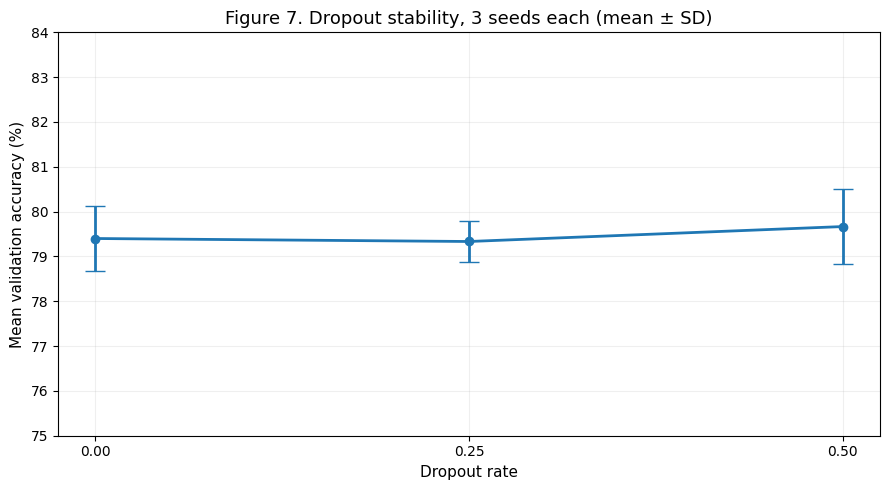

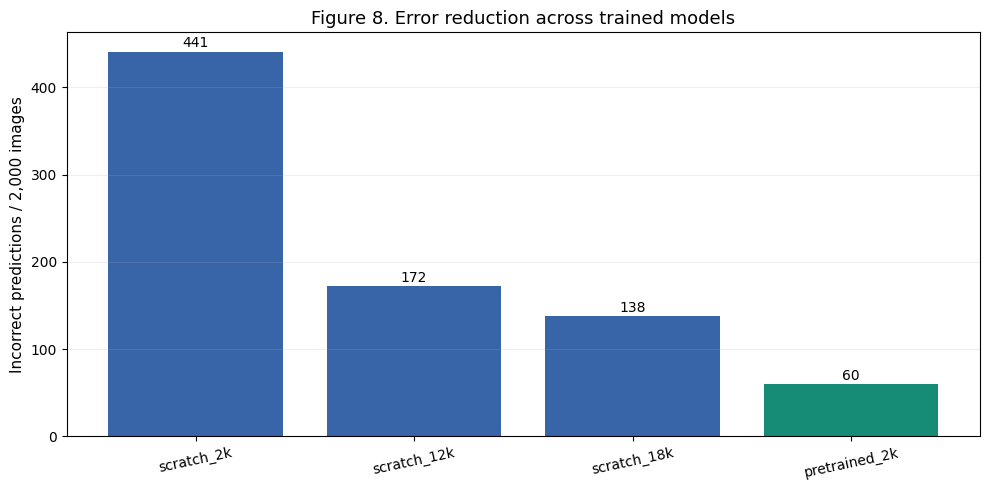

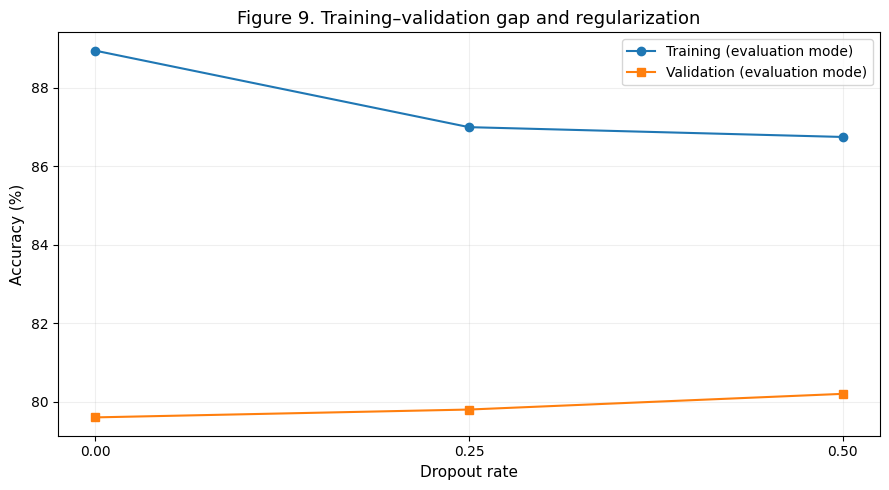

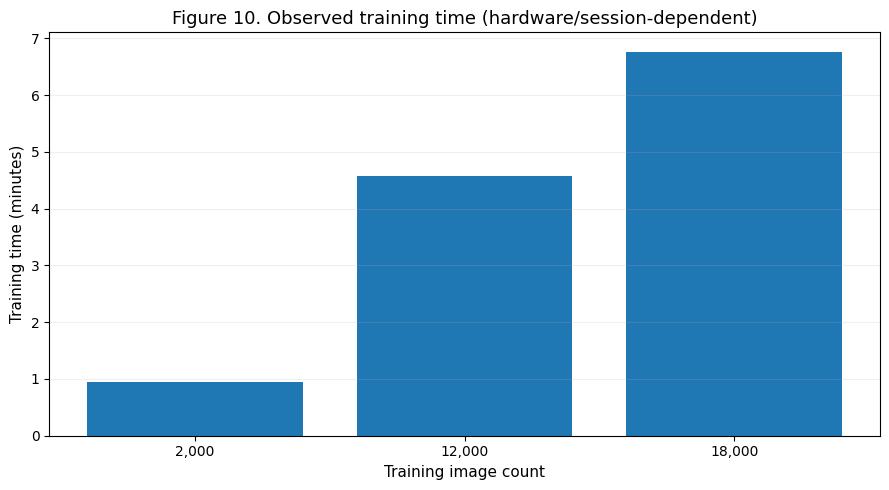

In [20]:
# Figure 7 — mean +/- sample standard deviation across predetermined random seeds.
plt.figure(figsize=(9,5))
plt.errorbar(seed_summary['Dropout'],seed_summary['Mean_Accuracy'],
             yerr=seed_summary['Std_Accuracy'],capsize=7,marker='o',linewidth=2)
plt.xticks([0,.25,.5]);plt.ylim(75,84)
plt.xlabel('Dropout rate');plt.ylabel('Mean validation accuracy (%)')
plt.title('Figure 7. Dropout stability, 3 seeds each (mean ± SD)')
plt.grid(alpha=.2)
save_plot('07_dropout_seed_stability.png')

# Figure 8 — actual misclassification counts on the same holdout 1.
error_plot=error_summary.sort_values('Incorrect',ascending=False)
plt.figure(figsize=(10,5))
bars=plt.bar(error_plot['Model'],error_plot['Incorrect'],
             color=['#3765a8' if 'scratch' in m else '#168c76' for m in error_plot['Model']])
for bar,v in zip(bars,error_plot['Incorrect']):
    plt.text(bar.get_x()+bar.get_width()/2,bar.get_height()+5,str(int(v)),ha='center')
plt.ylabel('Incorrect predictions / 2,000 images');plt.title('Figure 8. Error reduction across trained models')
plt.xticks(rotation=12);plt.grid(axis='y',alpha=.2)
save_plot('08_holdout1_misclassification_counts.png')

# Figure 9 — dropout overfitting signal, evaluation mode on training images.
plt.figure(figsize=(9,5))
plt.plot(dropout_results['Dropout Rate'],dropout_results['Training Accuracy (%)'],
         marker='o',label='Training (evaluation mode)')
plt.plot(dropout_results['Dropout Rate'],dropout_results['Validation Accuracy (%)'],
         marker='s',label='Validation (evaluation mode)')
plt.xticks([0,.25,.5]);plt.xlabel('Dropout rate');plt.ylabel('Accuracy (%)')
plt.title('Figure 9. Training–validation gap and regularization')
plt.legend();plt.grid(alpha=.2)
save_plot('09_dropout_train_val_gap.png')

# Figure 10 — supplementary 2K vs 12K vs 18K scratch training efficiency.
times=[]
for n in (2000,12000,18000):
    folder=CORE_FOLDERS[('Scratch',2000)] if n==2000 else EXT/f'cnn_{n}'
    data=pd.read_csv(folder/'results_summary.csv').iloc[0]
    if 'training_minutes' in data and pd.notna(data['training_minutes']):
        times.append((n,float(data['training_minutes'])))
if len(times)>=2:
    x=[n for n,_ in times]; y=[mins for _,mins in times]
    plt.figure(figsize=(9,5));plt.bar([f'{n:,}' for n in x],y)
    plt.ylabel('Training time (minutes)');plt.xlabel('Training image count')
    plt.title('Figure 10. Observed training time (hardware/session-dependent)')
    plt.grid(axis='y',alpha=.2)
    save_plot('10_training_time.png')
else:
    print('Not enough reliable saved runtime measurements for a training-time chart.')

## 13. Final integrity summary and code deliverables

The final consolidated files are generated from the verified **currently available checkpoints**. They do not reuse outdated hand-entered numbers from earlier notebook reruns. We retain the original recorded runs in the unchanged source notebook as a historical audit trail.

**Interpretation guardrails:** A one-image difference on a 500-image validation set equals **0.2 percentage points**; performance with dropout rates 0.0/0.25/0.5 is extremely similar and three seeds do not prove a universally optimal rate. The suspected `cat.4085.jpg` label error and out-of-scope logo are flagged, but **original benchmark scores remain unchanged**. These experiments assess practical CNN configurations; they are not a controlled causal experiment isolating pretraining, data size, and optimization budget independently.

In [21]:
all8_results.to_csv(VIS/'master_eight_model_comparison.csv',index=False)
seed_summary.to_csv(VIS/'seed_stability_summary.csv',index=False)
error_summary.to_csv(VIS/'error_counts.csv',index=False)

core_only=all8_results[all8_results['Training Images']<=2000]
scratch=core_only[core_only['Model Type']=='Scratch'].sort_values('Training Images')
pretrained=core_only[core_only['Model Type']=='Pretrained'].sort_values('Training Images')
scratch_gain=scratch['Validation Accuracy (%)'].iloc[-1]-scratch['Validation Accuracy (%)'].iloc[0]
pretrained_gain=pretrained['Validation Accuracy (%)'].iloc[-1]-pretrained['Validation Accuracy (%)'].iloc[0]
pretrained_test=float(all8_results.query("`Model Type`=='Pretrained' and `Training Images`==2000")['Original Test Accuracy (%)'].iloc[0])
scratch18_test=float(all8_results.query("`Model Type`=='Scratch' and `Training Images`==18000")['Original Test Accuracy (%)'].iloc[0])
summary_lines=[
    f'Required scratch 1K→2K validation gain: {scratch_gain:+.2f} percentage points.',
    f'Required pretrained 1K→2K validation gain: {pretrained_gain:+.2f} percentage points.',
    f'Original test accuracy — pretrained 2K: {pretrained_test:.2f}%; scratch 18K: {scratch18_test:.2f}%.',
    f'Pretrained 2K minus scratch 18K original-test difference: {pretrained_test-scratch18_test:+.2f} points.',
    f'Largest scratch training size: 18,000; original professor-required pool: 2,000.',
    'Each sample size was trained with a fresh model initialization; pretrained models reused ImageNet visual features.',
    'Checkpoint selection used lowest loss on the original 500-image validation sample.',
    'Holdout 1 (four-model robustness analysis) and holdout 2 (dropout sensitivity) are independent, distinct image cohorts.',
    'Test results are final/descriptive; do not optimize models on their scores.',
    'Possible source-label issue: cat.4085.jpg visually depicts a dog; scores retain supplied labels.',
    'Cross-partition filename overlap checked; SHA-256 exact duplicate audit saved separately.',
]
(VIS/'analysis_highlights.txt').write_text('\n'.join(summary_lines))
print('\n'.join(summary_lines))
print('\nSaved tables:')
for file in sorted(VIS.glob('*.csv')):
    print(' ',file.name)
print('\nSaved figures:')
for file in sorted(VIS.glob('*.png')):
    print(' ',file.name)
print('\nNOTE: Export/save this Kaggle notebook WITH outputs and preserve all /kaggle/working checkpoint/CSV/PNG artifacts.')

Required scratch 1K→2K validation gain: +2.40 percentage points.
Required pretrained 1K→2K validation gain: +0.20 percentage points.
Original test accuracy — pretrained 2K: 96.40%; scratch 18K: 93.20%.
Pretrained 2K minus scratch 18K original-test difference: +3.20 points.
Largest scratch training size: 18,000; original professor-required pool: 2,000.
Each sample size was trained with a fresh model initialization; pretrained models reused ImageNet visual features.
Checkpoint selection used lowest loss on the original 500-image validation sample.
Holdout 1 (four-model robustness analysis) and holdout 2 (dropout sensitivity) are independent, distinct image cohorts.
Test results are final/descriptive; do not optimize models on their scores.
Possible source-label issue: cat.4085.jpg visually depicts a dog; scores retain supplied labels.
Cross-partition filename overlap checked; SHA-256 exact duplicate audit saved separately.

Saved tables:
  error_counts.csv
  master_eight_model_comparison

### 13.1 Model-specific exact-content leakage audit — verified separately

The preceding global SHA-256 check flags any byte-identical files assigned to different dataset partitions. A **subsequent model-specific check was executed in Kaggle**, comparing the actual training selection of each model with only the evaluation cohorts on which that model was measured. Its supplied output has been preserved as CSV in `../audit/` and can be reproduced using `../src/model_specific_duplicate_audit.py` (run after the notebook has initialized its dataframes).

**Result of the separately executed audit:** **28 / 28 model–evaluation pairs passed with zero shared SHA-256 hashes**. The 1K, 1.5K and 2K core training selections each contained zero repeated file contents; the 12K and 18K extended training selections contained respectively **3** and **4** redundant image occurrences. The extra 2,000-image validation set contained **one byte-identical pair**. In total, **five exact-duplicate groups involved eleven filenames**.

One content group crossed extended training and *dropout holdout 2*. However, the models evaluated on dropout holdout 2 were trained on the 2K core pool, while extended-training models were evaluated on different held-out cohorts. **No actual evaluated model/train–evaluation pair showed exact duplicate leakage.** The duplicate groups remain a dataset-quality limitation, and results have not been edited retrospectively.

**Audit scope:** SHA-256 detects only byte-identical files. It does not rule out visually near-identical images stored with different encodings, nor does it resolve source-label errors such as the manually identified suspicious `train/cat.4085.jpg`. Detailed filenames, hash values and the 28 audited comparisons are included as separate CSVs and documented in `../docs/DATA_INTEGRITY.md`.

*Provenance: these audit findings were supplied from a later, separately executed Kaggle check; this markdown cell is documentation, not a claim that the audit appears in earlier execution outputs.*


## 14. What to submit and preserve

- **Code:** this executed and documented `.ipynb` notebook; optionally export to `.py` in Kaggle as a convenience.
- **Reproducibility evidence:** frozen split manifests, `.keras` best checkpoints, training histories, environment JSON, and CSV results (may be stored in Kaggle version outputs or an archive; do not upload giant image datasets unnecessarily to GitHub).
- **Figures:** the master dashboard PNGs and selected error galleries. Include the class counts and duplicate audit status in the written submission.
- **Required rendered artifact:** the instructor separately requires a well-documented rendered HTML/PDF/Word output and a summary graph or table. **This notebook is the code artifact, not that separate report.**
- **Repository:** use the existing course repository, new `Assignment 2/` folder; submit the repository URL ending in `.git` on Canvas.

*The original exploratory notebook should be retained as an archive. This refactored notebook preserves its experimental scope, but executing it may produce slightly different metrics due to GPU nondeterminism or runtime versions. Keep one coherent run's checkpoints, histories and results together.*